# Wizualna kontrola jakości odlewów - klasyfikacja obrazów kontra detekcja anomalii
**Zadanie główne**: Zbudować klasyfikator obrazów rozróżniający element wadliwy i poprawny, a następnie
porównać go z podejściem opartym na detekcji anomalii, uczonym wyłącznie na próbkach poprawnych - i ocenić,
które podejście lepiej pasuje do realiów kontroli jakości.

**Wprowadzenie**: zagadnienie pochodzi z obszaru przemysłu i dotyczy "computer vision" w kontoroli jakości odlewów. Zadanie polega na porównaniu klasyfikacji obrazów (uczonej na obu klasach: dobre i wadliwe) z detekcją anomalii (uczoną wyłącznie na elementach poprawnych). Dlaczego mielibyśmy rozwiązać tak postawiony problem? Wynika z realnych wyzwań panujących na liniach produkcyjnych. W realiach fabrycznych zdecydowana większość produkowanych odlewów jest poprawna (często >99%), a elementy wadliwe pojawiają się sporadycznie. Skutkuje to pojawieniem się skrajnie niezbalansowanych danych. Klasyfikator potrzebuje dużej liczby reprezentatywnych przykładów obu klas. Zebranie dużej ilości zdjęć zróżnicowanych wad bywa niezwykle trudne lub wręcz niemożliwe np. na na nowo uruchomionej linii produkcyjnej. Wady odlewnicze mogą przyjmować najróżniejsze formy: pęcherze gazowe, pęknięcia skurczowe, niedolewy czy wtrącenia żużlowe. Klasyfikator uczy się rozpoznawać konkretne rodzaje wad pokazane w treningu. Jeśli pojawi się nowa, niespotykana dotąd wada, klasyfikator może ją błędnie zaklasyfikować jako element poprawny (false negative). W przypadku detekcji anomalii model uczy się wzorca „jak wygląda idealny odlew”. Każde odstępstwo od tej normy traktuje jako anomalię, dzięki czemu potrafi wykryć dowolną, nawet zupełnie nową wadę, bez konieczności wcześniejszego widzenia jej na treningu. Detekcja anomalii drastycznie redukuje problem precyzyjnego klasyfikowania i opisania rodzajów wad, ponieważ do jej wytrenowania potrzebne są wyłącznie poprawne próbki, które można łatwo pozyskać masowo z bieżącej produkcji.

**Konkluzja:** Szukamy odpowiedzi na pytanie czy bardziej opłaca się zbierać i etykietować wady pod klasyfikator (uzyskując wyższą specyficzność (odsetek prawdziwie negatywnych) kosztem elastyczności), czy lepiej wdrożyć szybką detekcję anomalii (akceptując ryzyko wyższego odsetka fałszywych alarmów ( false positives)). Elastyczność rozumiemy łatwość zaadaptacji do zmian, ponieważ wystarczy dostarczyć nową serię poprawnych wzorców, zamiast opisywać wszystkie możliwe scenariusze awarii.


**Co zyskamy wdrożając to rozwiązania?**

Wdrożenie detekcji anomalii (w miejsce klasyfikatora) generuje wartość biznesową i operacyjną w kilku obszarach.
1. Likwiduje konieczość zbierania wad - brak oczekiwania na odpowiednio duża próba uszkodzonych odlewów. Model uczony jest wyłącznie na poprawnych produktach, które są dostępne od pierwszego dnia uruchomienia produkcji
2. Ochrania przed nowymi, nieznanymi typami wadami - nowa wada może być przeoczona przez klasyfikator. Natomiast, detekcja anomalii wyłapuje każde odstępstwo od normy, chroniąc firmę przed wypuszczeniem wadliwej partii na rynek i kosztami reklamacji.
3. Gwarantuje jakość - przesuwa priorytet na wyłapywanie wszystkich odchyleń minimalizując ryzyko błędów typu *false negative* (przepuszczenie wadliwego elementu).
4. Obniżasz koszt etykietowania danych - eliminuje potrzebę angażowania kontrolerów jakości do ręcznego opisywania i kategoryzowania każdego rodzaju uszkodzenia na zdjęciach treningowych.
5. Daje elastyczność przy zmianie asortymentu - przy przejściu na nowy model odlewu wymagane jest jedynie zebranie nowej serii zdjęć poprawnych produktów, co znacznie upraszcza utrzymanie i aktualizację systemu.

**Podsumowanie wartości**
Główną wartością jest redukcja ryzyka biznesowego: za cenę nieco wyższej liczby fałszywych alarmów (które można szybko zweryfikować ręcznie), firma zyskuje pełną elastyczność i natychmiastową gotowość systemu do wykrywania dowolnych wad bez ciągłych i kosztownych prac nad bazą danych.

**Jakie dane są dostępne?**

Zbiór danych: Casting Product Image Data for Quality Inspection, Kaggle - obrazy wirników pomp zatapialnych,
Zbiór zawiera 1300 obrazów, każdy 512×512 pikseli w odcieniach szarości. Zbiór dzieli się na dwie kategorie, mianowicie na uszkodzone i nieuszkodzone wirniki.

Adres pod którym dane są dostępne.

https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product

Acknowledgements
We wouldn't be here without the help of PILOT TECHNOCAST, Shapar, Rajkot. we have to thank them for constant support and allowing us to work for this problem.

**Zadania ML (machine learning) a problem biznesowy**

Problemem biznesowym jest zmniejszenie liczby braków i reklamacji (niższe koszty) oraz zagwarantowanie jakości która przekłada się na reputację marki. Zadanie ML polega na przygotowanie modelu klasyfikatora oraz modelu detekcji anomalii, ich porównanie wraz z uzasadnioną rekomendacją, który model wybrać gdy jest mało wad i są nieprzewidywalne.

**Jak wygląda obecnie detekcja wad?**

Niestety, nie istnieje opis jak wygląda obecnie wykrywanie wad odlewów.

**Ukryte założenia**
1. Możliwe jest określenie danych wyjściowych (tutaj wad) na podstawie danych wejściowych (tutaj zdjęć uzkodzonych i poprawnych wirników)
2. Zebrane dane są wystarczające aby określić związek między danymi wejściowymi a wyjściowymi

**Środowisko**

T4 GPU

In [ ]:
import kagglehub
from pathlib import Path
import os
import tensorflow as tf
import hashlib
from collections import defaultdict
import matplotlib.pyplot as plt
from PIL import Image
import random
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


##Wczytanie i podgląd danych


Zbiór danych : zdjęcia ppkazujące widok z góry na wirnik pompy głębinowej. Przesłane obrazy są w formacie 512x512 w skali szarości i nie są augmentowane. Zbiór zawiera łącznie 1300 zdjęć w tym: 519 zdjęć poprawnych wirników (ok_front) oraz 781 zdjęć wirników uszkodzonych (def_front).

In [ ]:


# Download latest version
path = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")

# local path location to the notebook output
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'real-life-industrial-dataset-of-casting-product' dataset.
Path to dataset files: /kaggle/input/real-life-industrial-dataset-of-casting-product


In [ ]:
# Bazowa ścieżka pobrana przez kagglehub (zapisana w zmiennej path)
base_path = Path(path)

# Ścieżka do podwójnie zagnieżdżonego folderu casting_512x512
data_dir = base_path / "casting_512x512" / "casting_512x512"

# Ścieżki do poszczególnych klas obrazów
def_front_path = data_dir / "def_front"
ok_front_path = data_dir / "ok_front"

print("Główny folder z danymi:", data_dir)
print("Folder z uszkodzonymi (def_front):", def_front_path)
print("Folder z poprawnymi (ok_front):", ok_front_path)


Główny folder z danymi: /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512
Folder z uszkodzonymi (def_front): /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/def_front
Folder z poprawnymi (ok_front): /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/ok_front


In [ ]:
#Sprawdzam ilość zdjęć w foldzerze z uszkodzonymi oraz poprawnymi elementami
for root, dirs, files in os.walk(data_dir):
    print(f'Folder: {root} -> Liczba plików: {len(files)}')

Folder: /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512 -> Liczba plików: 0
Folder: /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/ok_front -> Liczba plików: 519
Folder: /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/def_front -> Liczba plików: 781


Zbiór zawiera łącznie 1300 zdjęć w tym: 519 zdjęć poprawnych wirników (ok_front) oraz 781 zdjęć wirników uszkodzonych (def_front).

##Wstępna obróbka danych (pre-processing)

Weryfikacja poprawności plików graficznych w zbiorze danych oraz automatyczne usuwania uszkodzonych obrazów.

In [ ]:
num_skipped = 0

# Pętla po plikach (os.walk): Przechodzi rekurencyjnie przez wszystkie podfoldery w
# data_dir i pobiera ścieżkę do każdego pliku (fpath).

for root, dirs, files in os.walk(data_dir):
    for fname in files:
        fpath = os.path.join(root, fname)
        try:
            # Odczyt i dekodowanie obrazu przez TensorFlow
            img_bytes = tf.io.read_file(fpath)
            _ = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)

        # Jeśli obraz jest uszkodzony, niekompletny lub ma niepoprawny format,
        # dekoder TensorFlow zgłosi błąd.
        except Exception:
            num_skipped += 1
            print(f"Uszkodzony obraz TF: {fpath}")
            os.remove(fpath)

print(f"Usunięto {num_skipped} uszkodzonych obrazów.")

Usunięto 0 uszkodzonych obrazów.


Nie wykryto uszkodzonych plików


**Weryfikacja duplikatów za pomocą sum kontrolnych MD5**

Aby upewnić się, że w zbiorze danych nie występują dokładnie takie same pliki (co mogłoby zafałszować wyniki podziału na zbiory treningowe, walidacyjne i testowe), obliczymy hash MD5 dla każdego pliku.

In [ ]:


def calculate_md5(filepath):
    """Oblicza sumę kontrolną MD5 dla podanego pliku."""
    hash_md5 = hashlib.md5()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# Słownik do grupowania ścieżek plików według ich hasha MD5
hashes = defaultdict(list)

# Iteracja po wszystkich plikach w zbiorze
all_files_to_check = list(data_dir.glob('**/*.jpeg')) + list(data_dir.glob('**/*.jpg'))

for filepath in all_files_to_check:
    file_hash = calculate_md5(filepath)
    hashes[file_hash].append(filepath)

# Znajdowanie duplikatów (hashe, które mają przypisane więcej niż 1 ścieżkę pliku)
duplicates = {hash_val: paths for hash_val, paths in hashes.items() if len(paths) > 1}

print(f"Przeanalizowano {len(all_files_to_check)} plików.")
if duplicates:
    print(f"Znaleziono {len(duplicates)} grup duplikatów!")
    for i, (hash_val, paths) in enumerate(duplicates.items(), 1):
        print(f"\nGrupa duplikatów #{i} (Hash: {hash_val}):")
        for path in paths:
            print(f"  - {path.relative_to(data_dir)}")
else:
    print("Sukces! Nie znaleziono żadnych zduplikowanych plików w całym zbiorze danych.")

Przeanalizowano 1300 plików.
Sukces! Nie znaleziono żadnych zduplikowanych plików w całym zbiorze danych.


**Podsumowanie zbioru danych:**

Zbiór nie posiada duplikatów ani uszkodzonych zdjęć.





**Przegląd zdjęć w zbiorze danych**.

Wyświetlimy partię zawierającą 4 zdjęć poprawnych wirników i 4 zdjęć uszkodzonych.

In [ ]:
# Konwertujemy zawartość katalogów na listy ścieżek do plików, aby móc pobrać pierwsze 4 obrazy
def_front_files = list(def_front_path.iterdir())
ok_front_files = list(ok_front_path.iterdir())

print("Przykładowe uszkodzone (def_front):")
for f in def_front_files[:4]:
    print(f.name)

print("\nPrzykładowe poprawne (ok_front):")
for f in ok_front_files[:4]:
    print(f.name)

Przykładowe uszkodzone (def_front):
cast_def_0_7446.jpeg
cast_def_0_6239.jpeg
cast_def_0_1589.jpeg
cast_def_0_7837.jpeg

Przykładowe poprawne (ok_front):
cast_ok_0_496.jpeg
cast_ok_0_5003.jpeg
cast_ok_0_5942.jpeg
cast_ok_0_6258.jpeg


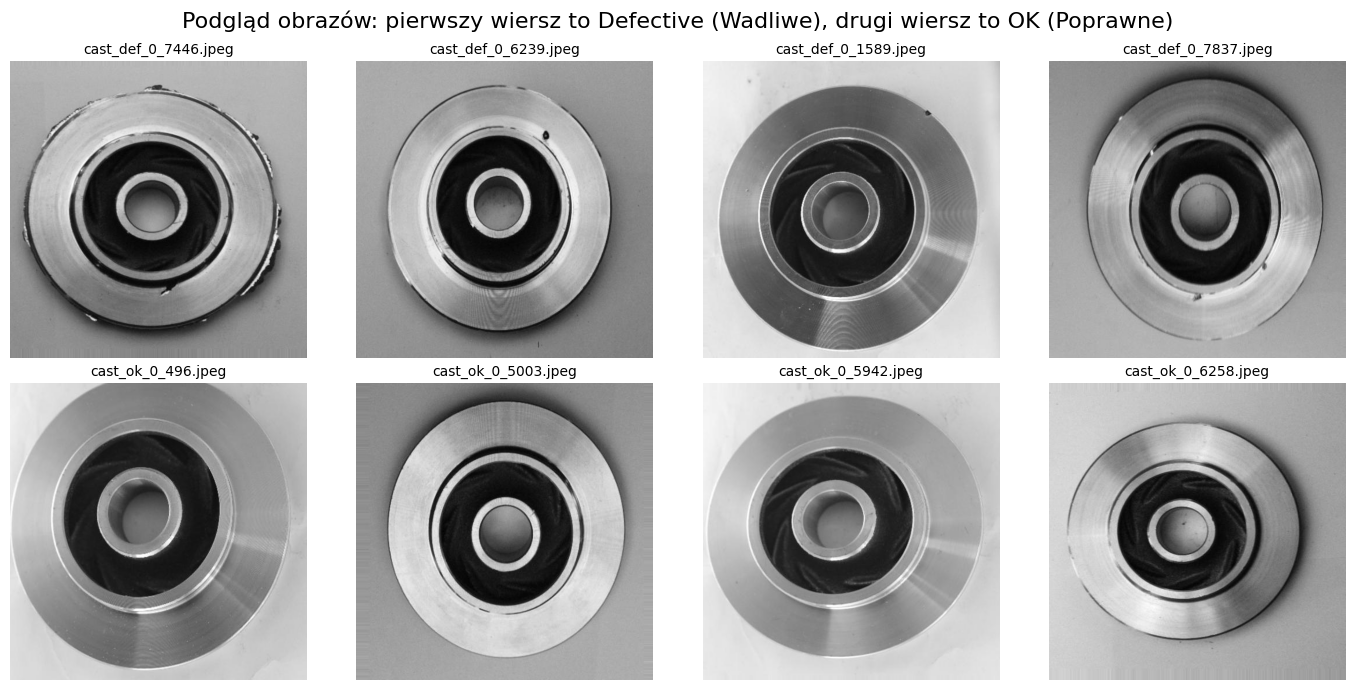

In [ ]:
# Przygotowanie siatki wykresów (2 wiersze, 4 kolumny)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle('Podgląd obrazów: pierwszy wiersz to Defective (Wadliwe), drugi wiersz to OK (Poprawne)', fontsize=16)

# Wyświetlanie 4 uszkodzonych obrazów w pierwszym wierszu (indeks 0)
for i in range(4):
    row = 0
    col = i
    img_path = def_front_files[i]
    img = Image.open(img_path)
    axes[row, col].imshow(img, cmap='gray')
    axes[row, col].set_title(img_path.name, fontsize=10)
    axes[row, col].axis('off')

# Wyświetlanie 4 poprawnych obrazów w drugim wierszu (indeks 1)
for i in range(4):
    row = 1
    col = i
    img_path = ok_front_files[i]
    img = Image.open(img_path)
    axes[row, col].imshow(img, cmap='gray')
    axes[row, col].set_title(img_path.name, fontsize=10)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

**Sprawdzenie poprawności opisu zdjęć**

1. Sprawdzenie, czy pliki fizycznie znajdują się w odpowiednich katalogach nadrzędnych
2. Pobranie większej próbki losowej

In [ ]:
import os

def_dir = "/kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/def_front"
ok_dir = "/kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/ok_front"

# Sprawdzenie, czy nazwy pasują do folderów
def_mismatch = [f for f in os.listdir(def_dir) if not f.startswith("cast_def_")]
ok_mismatch = [f for f in os.listdir(ok_dir) if not f.startswith("cast_ok_")]

print("Niezgodności w wadliwych:", len(def_mismatch))
print("Niezgodności w poprawnych:", len(ok_mismatch))

Niezgodności w wadliwych: 0
Niezgodności w poprawnych: 0


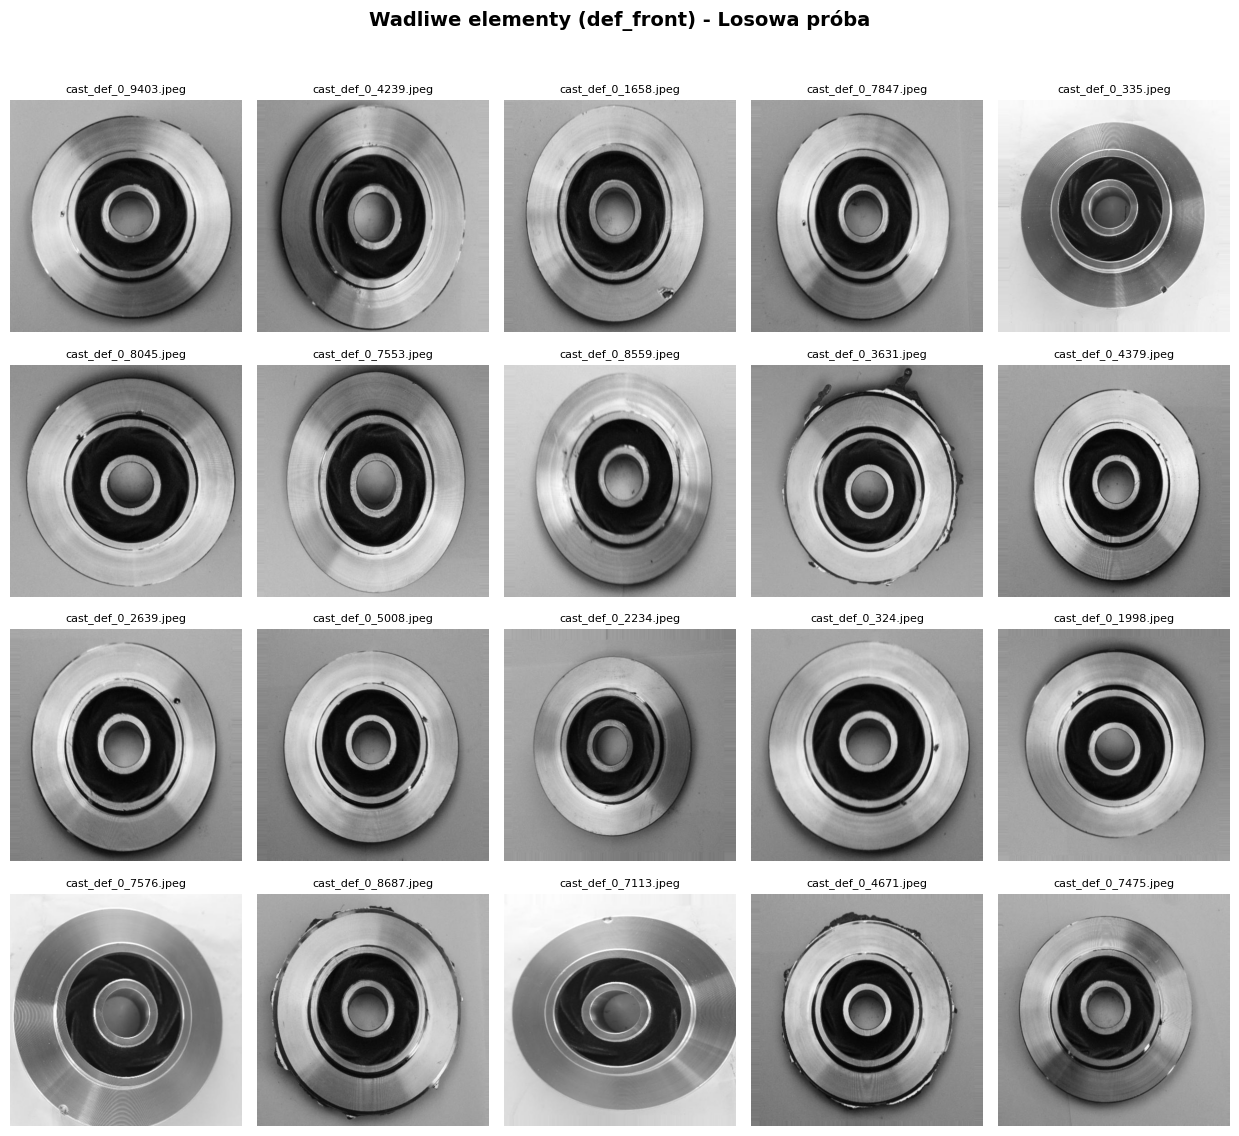

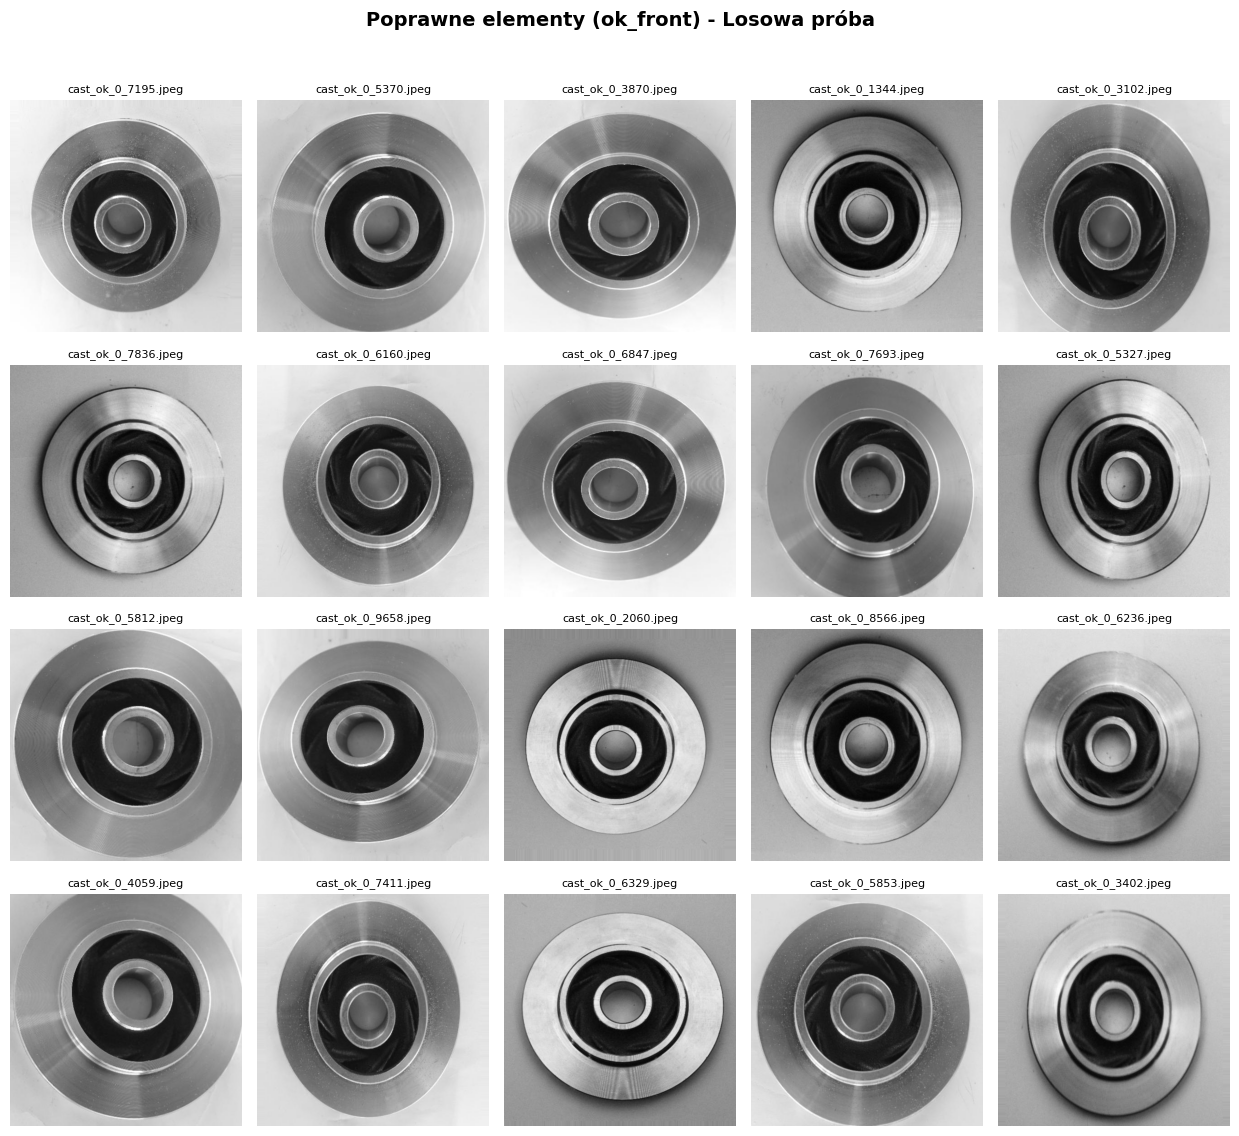

In [ ]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Ustawienie ziarna losowości dla pełnej powtarzalności wyników
random.seed(42)

# Ścieżki do folderów w środowisku Colab/Kaggle
base_dir = "/kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512"
def_dir = os.path.join(base_dir, "def_front")
ok_dir = os.path.join(base_dir, "ok_front")

# Pobranie list plików graficznych
def_files = [os.path.join(def_dir, f) for f in os.listdir(def_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
ok_files = [os.path.join(ok_dir, f) for f in os.listdir(ok_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# Liczba próbek do wylosowania (możesz ustawić np. 20 lub więcej)
n_samples = 20
sampled_def = random.sample(def_files, min(n_samples, len(def_files)))
sampled_ok = random.sample(ok_files, min(n_samples, len(ok_files)))

def plot_images_grid(file_paths, main_title, cols=5):
    """Funkcja pomocnicza rysująca obrazy w dynamicznej siatce (wiersze x kolumny)"""
    n = len(file_paths)
    rows = (n + cols - 1) // cols  # Automatyczne wyliczenie liczby wierszy

    # Dynamiczne dopasowanie rozmiaru figury
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.8))
    axes = axes.flatten()

    for i, file_path in enumerate(file_paths):
        img = mpimg.imread(file_path)
        axes[i].imshow(img, cmap='gray' if len(img.shape) == 2 else None)
        # Zmniejszona czcionka i wyświetlanie samej nazwy pliku dla czytelności
        axes[i].set_title(os.path.basename(file_path), fontsize=8)
        axes[i].axis('off')

    # Wyłączenie nadmiarowych pól w siatce, jeśli liczba zdjęć nie wypełnia jej do końca
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    fig.suptitle(main_title, fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Generowanie czytelnych siatek dla obu kategorii
plot_images_grid(sampled_def, "Wadliwe elementy (def_front) - Losowa próba", cols=5)
plot_images_grid(sampled_ok, "Poprawne elementy (ok_front) - Losowa próba", cols=5)

**Wnioski:**

Na podstawie pobranej próbki przyjmujemy, że opisy zdjęć są poprawne, tzn. że zdjęcia zaczynające swoją nazwę na cast_def_0_ przedstawiają uszkodzone wirniki a zdjęcia zaczynajace swoją nazwę na cast_ok_0 ilustrują poprawne wirniki.


## Ustalanie miary sukcesu

Czy ten zbiór jest zbilansowany?

Zbiór nie jest idealnie zbilansowany, ale różnica jest umiarkowana. Klasa uszkodzonych wirników (def_front) stanowi $60\%$ zbioru, a klasa sprawnych (ok_front) $40\%$.

Czy zbiór wymaga balansowania?


Proporcja 60/40 nie wymaga zaawansowanych technik balansowania.

Biorąc pod uwagę strukturę tego zbioru danych (klasyfikacja binarna: 519 próbek poprawnych ok_front oraz 781 próbek wadliwych def_front), dane są stosunkowo zrównoważone liczbowo. Jednak w realiach przemysłowych (kontrola jakości) zwykła dokładność ogólna (accuracy) rzadko bywa wystarczającą miarą sukcesu.

Przyjęte miary:
1. Czułość (Sensitivity/Recall) - mierzy jaki procent wszystkich faktycznie wadliwych odlewów (def_front) został poprawnie wykryty przez model (odsetek prawdziwie pozytywnych / true positive). Nie chcemy przeoczyć wadliwego elementu (False Negative) i wysłać go do klienta generując ogromne koszty reklamacji i niszcząc reputację firmy. Dążymy do tego, aby Recall dla wad był bliski 100%.
2. Precyzja (Precision) - mierzy jaki procent odlewów wskazanych przez model jako wadliwe faktycznie nimi było. Wskazuje jak często model wszczyna fałszywy alarm (False Positive), odrzucając dobre odlewy jako złom. Chcemy aby Precision był jak najwyższy.
3. F1 score - mierzy średnią harmoniczną między precyzją a czułością. Łączy obie powyższe miary w jeden wskaźnik, pozwalając ocenić, czy model dobrze balansuje między przepuszczaniem wad a odrzucaniem dobrych sztuk.

Podział zbioru w celu oceny modelu:

Dla potrzeb oceny modelu klasyfikacji obrazów zbiór będzie podzielony na 3 części: treningową, walidacyjną (sprawdzającą) oraz testową w proporcji 70% / 15% / 15%. Kluczowym aspektem podziału na trzy podzbiory jest zapobieganie 'wyciekowi' danych. Zbiór treningowy służy do trenowania modelu poprzez wyliczenie błędu (funkcja straty/loss funtion), następnie za pomocą korekty wag (wyprowadzania gradientów i wstępnej propagacji błędów / backpropagation) dostosowanie filtrów splotowych, by nauczyć się rozpoznawać krawędzie, pęknięcia czy kształty. Zbiór sprawdzający wykrywa przeuczenie (Overfitting). Wprowadzenie mechanizmu Early Stopping pozwala przerwać trening w momencie, gdy błąd na zbiorze walidacyjnym przestaje maleć. Finalnie dzięki zbiorowi psrawdzającemu możemy stroić hiperparametry takie jak dobór tempa uczenia (learning rate), rozmiar batcha, poziomu dropoutu czy liczba filtrów w warstwach splotowych. Niemniej, takie strojenie modelu powoduje, że część informacji o danych sprawdzających "przecieka" do modelu. Wielokrotne strojenie parametrów spowoduje wielokrotny 'przeciek". Ostatecznie, to spowoduje, że model sztucznie będzie sobie bardzo dobrze radzić na zbiorze sprawdzającym ze względu na optymalizację pod tym kątem. Remedium na to  jest posiadanie zbioru testowego, któego model nie nidgy wcześniej nie widział. Zbiór ten jest niedostępny aż do całkowitego zakończenia prac nad modelem. Gdy model jest już w pełni wytrenowany, a jego hiperparametry ustalone, model testuje się go jednorazowo na zbiorze testowym, aby uzyskać bezstronną ocenę skuteczności (np. ostateczne F1-score, Precision, Recall).

In [ ]:
import matplotlib.image as mpimg

# Wczytanie przykładowego zdjęcia z naszego zbioru odlewów
img = mpimg.imread('/kaggle/input/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/ok_front/cast_ok_0_496.jpeg')

print("Kształt obrazu (shape):", img.shape)
# Wynik dla obrazu w skali szarości: (512, 512)
# Wynik dla obrazu kolorowego RGB: (512, 512, 3)

Kształt obrazu (shape): (512, 512, 3)


In [ ]:
import random
import numpy as np
from PIL import Image

# Ustawienie ziarna losowości dla powtarzalności wyników
random.seed(42)

# Losowy wybór przykładowego obrazu z każdej klasy
sample_def_path = random.choice(def_front_files)
sample_ok_path = random.choice(ok_front_files)

# Odczyt właściwości oraz kształtu (shape)
with Image.open(sample_def_path) as img_def:
    def_size = img_def.size
    def_format = img_def.format
    def_mode = img_def.mode
    def_shape = np.array(img_def).shape  # Kształt tablicy NumPy

with Image.open(sample_ok_path) as img_ok:
    ok_size = img_ok.size
    ok_format = img_ok.format
    ok_mode = img_ok.mode
    ok_shape = np.array(img_ok).shape   # Kształt tablicy NumPy

print("Próbka Defective (Wadliwa):")
print(f" - Plik: {sample_def_path.name}")
print(f" - Wymiary PIL (szerokość x wysokość): {def_size}")
print(f" - Kształt NumPy (shape): {def_shape} (wysokość, szerokość, [kanały])")
print(f" - Format pliku: {def_format}")
print(f" - Tryb kolorów: {def_mode} (L oznacza skalę szarości / Grayscale)")

print("\nPróbka OK (Poprawna):")
print(f" - Plik: {sample_ok_path.name}")
print(f" - Wymiary PIL (szerokość x wysokość): {ok_size}")
print(f" - Kształt NumPy (shape): {ok_shape} (wysokość, szerokość, [kanały])")
print(f" - Format pliku: {ok_format}")
print(f" - Tryb kolorów: {ok_mode}")

Próbka Defective (Wadliwa):
 - Plik: cast_def_0_9403.jpeg
 - Wymiary PIL (szerokość x wysokość): (512, 512)
 - Kształt NumPy (shape): (512, 512, 3) (wysokość, szerokość, [kanały])
 - Format pliku: JPEG
 - Tryb kolorów: RGB (L oznacza skalę szarości / Grayscale)

Próbka OK (Poprawna):
 - Plik: cast_ok_0_2054.jpeg
 - Wymiary PIL (szerokość x wysokość): (512, 512)
 - Kształt NumPy (shape): (512, 512, 3) (wysokość, szerokość, [kanały])
 - Format pliku: JPEG
 - Tryb kolorów: RGB


In [ ]:
# Ustawienie globalnego ziarna losowości dla pełnej powtarzalności
import keras
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)  # Kluczowe dla nowych wersji Keras/TensorFlow

# Włączenie pełnego determinizmu operacji na GPU (zapobiega drobnym różnicom w obliczeniach kart T4)
tf.config.experimental.enable_op_determinism()

# Przygotowanie pełnej listy ścieżek oraz etykiet (0 dla ok_front, 1 dla def_front)
all_filepaths = ok_front_files + def_front_files
all_labels = [0] * len(ok_front_files) + [1] * len(def_front_files)

# Podział na zbiór treningowy (70%) oraz tymczasowy zbiór (30% - walidacyjny + testowy)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_filepaths,
    all_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

# Podział tymczasowego zbioru po połowie na walidacyjny (15% całości) i testowy (15% całości)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

# Podsumowanie liczebności zbiorów
split_summary = pd.DataFrame({
    'Zbiór': ['Treningowy (70%)', 'Walidacyjny (15%)', 'Testowy (15%)', 'Suma'],
    'Liczba OK': [
        train_labels.count(0),
        val_labels.count(0),
        test_labels.count(0),
        all_labels.count(0)
    ],
    'Liczba Defect': [
        train_labels.count(1),
        val_labels.count(1),
        test_labels.count(1),
        all_labels.count(1)
    ],
    'Łącznie': [
        len(train_labels),
        len(val_labels),
        len(test_labels),
        len(all_labels)
    ]
})

display(split_summary)

,Zbiór,Liczba OK,Liczba Defect,Łącznie
0,Treningowy (70%),363,547,910
1,Walidacyjny (15%),78,117,195
2,Testowy (15%),78,117,195
3,Suma,519,781,1300


# Przygotowanie modelu klasyfikującego

**Budowa modelu**

Model CNN (Convolutional Neural Network) składa się z sekwencji warstwa Conv2 oraz MaxPooling2D. Istotne jest uwaga, że danymi wejściowymi jest tensor of wymiarach (zdjęcie_wysokość, zdjęcie_szerokość, zdjęcie_kanały). W poniższym przypadku konfiguracja będzie przetwarzała zdjęcia o wymiarach (512,512,3). Danymi wyjściowymi każdej warstwy Conv2 oraz MaxPooling2D jest tensor 3D o wumiarach (wysokość szerokość, liczba kanałów). Szerokość oraz wysokość ulegają zmniejszeniu im dalej jesteśmy w modelu. Ilość kanałów jest kontrolowana przez pierwszy argument podany w warstwie Conv2D (32, 64 128, 256, 512). Po ostatniej wartwie Conv2D otrzymujemy dane wyjściowe o wymiarach (28,28, 512) - 28 x 28 mapę cech z 256 kanałami. Następnym krokiem jest przekazaniem ich do klasyfikatora, który przetwarza wektor 1D. Pomostem między przestrzenią 3D a 1D jest wartstwa GlobalAveragePooling2D, która weźmie średnie wartości każdej mapy cech o wymiarach 28 x 28 i stworzy wektor o wymiarach (512,). Końcowa wartstwa ma jedno wyjście oraz sigmoid jako funkcję aktywacji.
Model zaczyna się normalizacją (rescaling) danych wejściowych polegających na przekształceniu wartości pikseli z zakresu $[0, 255]$ do przedziału $[0, 1]$, co jest kluczowe dla stabilności treningu sieci (jeśli dane wejściowe mają duże wartości (do 255), gradienty mogą stać się niestabilne, co drastycznie spowalnia lub uniemożliwia poprawny trening modelu).

**Ustalenie modelu bazowego**

Celem jest ustalenie obiektywnej miary, by stwierdzić, czy bardziej zaawansowane techniki (lub przejście na detekcję anomalii) wnoszą realną wartość. Będzie to klasyfikator CNN bez augmentacji i zaawansowanego dostrajania, na tych samych podziałach danych.


In [ ]:
# Funkcja pomocnicza do wczytywania i dekodowania obrazów
def load_and_preprocess_image(path, label):
    image_bytes = tf.io.read_file(path)
    # Dekodowanie obrazu JPEG do formatu RGB i zmiana rozmiaru do 512x512
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, [512, 512])
    return image, label

# Konwersja ścieżek (obiektów PosixPath) na ciągi znaków (str)
train_paths_str = [str(p) for p in train_paths]
val_paths_str = [str(p) for p in val_paths]
test_paths_str = [str(p) for p in test_paths]

# Tworzenie obiektów tf.data.Dataset ze ścieżek i etykiet
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths_str, train_labels))
val_dataset = tf.data.Dataset.from_tensor_slices((val_paths_str, val_labels))
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths_str, test_labels))

# Mapowanie funkcji wczytującej obrazy
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
val_dataset = val_dataset.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
test_dataset = test_dataset.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)

# Przygotowanie ostatecznych zbiorów danych (batch, prefetch)
BATCH_SIZE = 16

train_dataset_before_aug = train_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE) # dane przed augmentacją
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Zbiory danych zostały pomyślnie utworzone i zoptymalizowane!")

Zbiory danych zostały pomyślnie utworzone i zoptymalizowane!


In [ ]:
import keras
from keras import layers

# Ustawienie ziarna losowości przed budową modelu
keras.utils.set_random_seed(42)

# Model bazowy: płytka sieć splotowa bez augmentacji i regularyzacji
inputs = keras.Input(shape=(512, 512, 3))

# Normalizacja pikseli do zakresu [0, 1] (ten krok zostawiamy zawsze)
x = layers.Rescaling(1.0 / 255)(inputs)

# Tylko 3 proste bloki splotowe o małej liczbie filtrów (16 -> 32 -> 64)
x = layers.Conv2D(filters=16, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

# Spłaszczenie cech i warstwa wyjściowa
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

baseline_model = keras.Model(inputs=inputs, outputs=outputs, name="baseline_cnn")

In [ ]:
summary = baseline_model.summary()
print(summary)

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 510, 510, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 255, 255, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 253, 253, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 124, 124, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,649 (92.38 KB)

 Trainable params: 23,649 (92.38 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
import tensorflow as tf

# Usunięto tf.keras.metrics.F1Score, ponieważ dla wyjścia binarnego 1D generuje on błąd wymiarów.
# F1-score będzie poprawnie wyliczany ręcznie i wizualizowany po zakończeniu treningu.
baseline_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)
print("Model został pomyślnie skompilowany ze zgodnymi metrykami.")

Model został pomyślnie skompilowany ze zgodnymi metrykami.


In [ ]:
# Połączenie EarlyStopping oraz ModelCheckpoint na jednej liście
callbacks = [
    # keras.callbacks.EarlyStopping(
    #     monitor="val_loss",
    #     patience=7,
    #     restore_best_weights=True
    # ),
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_baseline.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

# Uruchomienie procesu uczenia
history_baseline = baseline_model.fit(
    train_dataset_before_aug,
    validation_data=val_dataset,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 87ms/step - accuracy: 0.6011 - loss: 0.6783 - precision: 0.6011 - recall: 1.0000 - val_accuracy: 0.6000 - val_loss: 0.6739 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.6011 - loss: 0.6644 - precision: 0.6011 - recall: 1.0000 - val_accuracy: 0.6000 - val_loss: 0.6575 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.6011 - loss: 0.6462 - precision: 0.6011 - recall: 1.0000 - val_accuracy: 0.6000 - val_loss: 0.6450 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.6011 - loss: 0.6344 - precision: 0.6011 - recall: 1.0000 - val_accuracy: 0.6000 - val_loss: 0.6350 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.6527 - loss: 0.6174 - precision: 0.6446 - recall: 0.9415 - val_accuracy: 0.6205 - val_loss: 0.6263

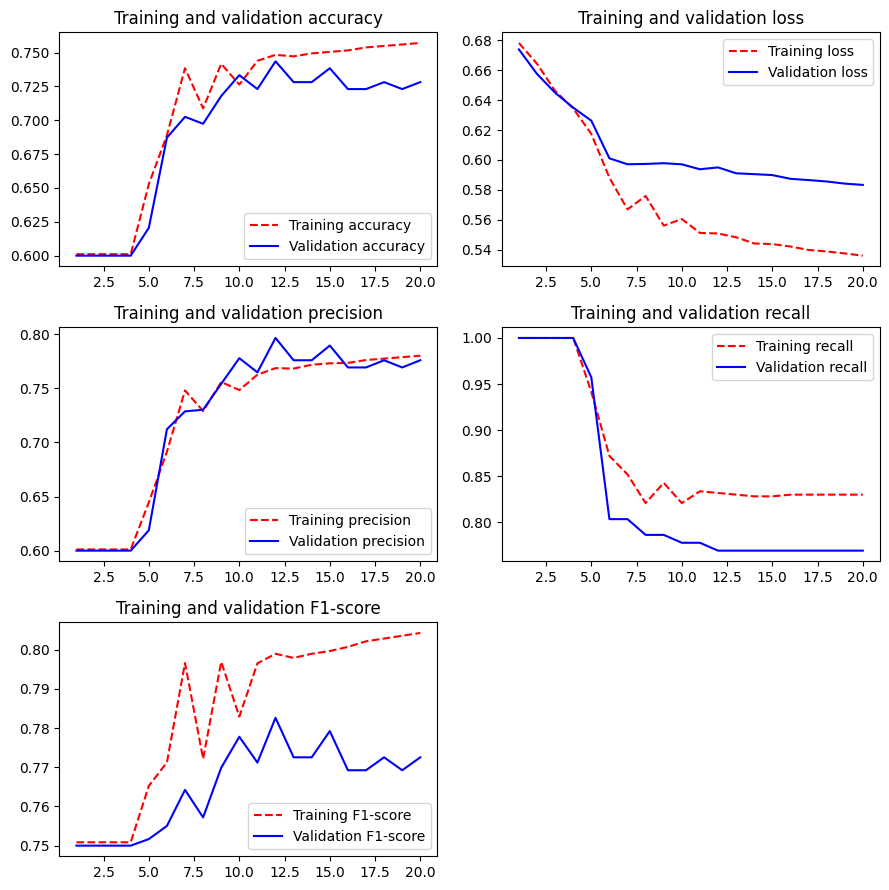

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Upewnij się, że komórka z treningiem (cell_id: lrxjXRZIQXV6) została wykonana pomyślnie przed tą komórką!
history = history_baseline

# Określenie liczby epok
epochs = range(1, len(history.history["loss"]) + 1)

# Pobranie podstawowych metryk
acc = history.history.get("accuracy", history.history.get("acc"))
val_acc = history.history.get("val_accuracy", history.history.get("val_acc"))

loss = history.history["loss"]
val_loss = history.history["val_loss"]

precision = history.history["precision"]
val_precision = history.history["val_precision"]

recall = history.history["recall"]
val_recall = history.history["val_recall"]

# Pobranie lub wyliczenie F1-score (dla treningu i walidacji)
if "f1_score" in history.history:
    f1 = history.history["f1_score"]
    val_f1 = history.history["val_f1_score"]
else:
    f1 = 2 * (np.array(precision) * np.array(recall)) / (np.array(precision) + np.array(recall) + 1e-7)
    val_f1 = 2 * (np.array(val_precision) * np.array(val_recall)) / (np.array(val_precision) + np.array(val_recall) + 1e-7)

# Tworzenie figury w układzie 3 wiersze x 2 kolumny (miejsce na 6 wykresów)
fig, axes = plt.subplots(3, 2, figsize=(9, 9))

# --- 1. Wykres Accuracy (wiersz 1, kolumna 1) ---
if acc:
    axes[0, 0].plot(epochs, acc, "r--", label="Training accuracy")
    axes[0, 0].plot(epochs, val_acc, "b", label="Validation accuracy")
    axes[0, 0].set_title("Training and validation accuracy")
    axes[0, 0].legend()

# --- 2. Wykres Loss (wiersz 1, kolumna 2) ---
axes[0, 1].plot(epochs, loss, "r--", label="Training loss")
axes[0, 1].plot(epochs, val_loss, "b", label="Validation loss")
axes[0, 1].set_title("Training and validation loss")
axes[0, 1].legend()

# --- 3. Wykres Precision (wiersz 2, kolumna 1) ---
axes[1, 0].plot(epochs, precision, "r--", label="Training precision")
axes[1, 0].plot(epochs, val_precision, "b", label="Validation precision")
axes[1, 0].set_title("Training and validation precision")
axes[1, 0].legend()

# --- 4. Wykres Recall (wiersz 2, kolumna 2) ---
axes[1, 1].plot(epochs, recall, "r--", label="Training recall")
axes[1, 1].plot(epochs, val_recall, "b", label="Validation recall")
axes[1, 1].set_title("Training and validation recall")
axes[1, 1].legend()

# --- 5. Wykres F1-score (wiersz 3, kolumna 1) ---
axes[2, 0].plot(epochs, f1, "r--", label="Training F1-score")
axes[2, 0].plot(epochs, val_f1, "b", label="Validation F1-score")
axes[2, 0].set_title("Training and validation F1-score")
axes[2, 0].legend()

# --- Ukrycie pustego 6. pola (wiersz 3, kolumna 2) ---
axes[2, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
test_model_baseline = keras.models.load_model("convnet_baseline.keras")
test_loss, test_acc, test_prec, test_rec = test_model_baseline.evaluate(test_dataset)

print(f"Test accuracy: {test_acc*100:.1f}%")
print(f"Test precision: {test_prec*100:.1f}%")
print(f"Test recall: {test_rec*100:.1f}%")
print(f"Test F1-score: {2 * (test_prec * test_rec) / (test_prec + test_rec)*100:.1F}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7692 - loss: 0.5137 - precision: 0.8396 - recall: 0.7607
Test accuracy: 76.9%
Test precision: 84.0%
Test recall: 76.1%
Test F1-score: 79.8


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step


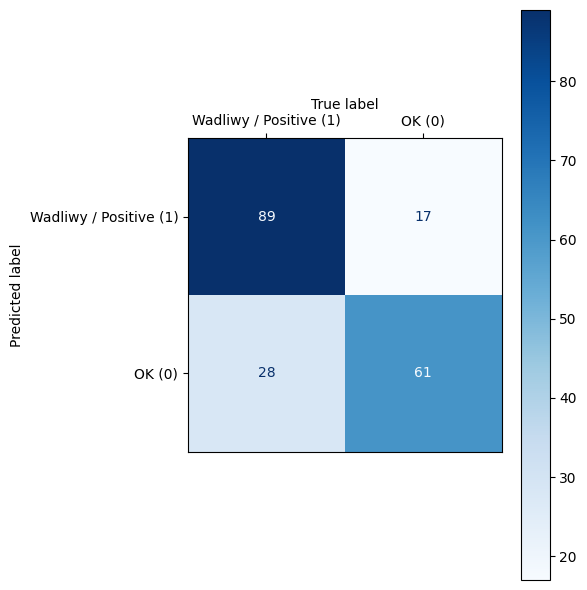

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

test_model = test_model_baseline

# Zebranie wszystkich prawdziwych etykiet i predykcji ze zbioru testowego
y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = test_model.predict(test_dataset)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

# 1. Kolejność labels=[1, 0] umieszcza klasę pozytywną (Wadliwy) w 1. wierszu i 1. kolumnie
# 2. Transpozycja (.T) zamienia osie: wiersze = Predicted, kolumny = True
cm = confusion_matrix(y_true, y_pred, labels=[1, 0]).T

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Wadliwy / Positive (1)", "OK (0)"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)

# Zaktualizowanie opisów osi po transpozycji
ax.set_ylabel("Predicted label")
ax.set_xlabel("True label")

# Przeniesienie etykiety "True label" oraz nazw kolumn na górę wykresu
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.tight_layout()
plt.show()

Przez pierwsze 4 epoki wartości Accuracy oraz Precision stoją w miejscu na poziomie 0.60, natomiast Recall wynosi 1.00 (100%), a F1-score utrzymuje się na poziomie 0.75. Oznacza to, że model w początkowej fazie klasyfikuje wszystkie badane elementy jako uszkodzone - stąd 60% trafności (odzwierciedlającej proporcję klas w zbiorze) i 100% czułości. Jednocześnie funkcja straty (Loss) systematycznie maleje (z ~0.68 do ~0.635), co dowodzi, że sieć po cichu dostosowuje wagi i przygotowuje się do właściwego rozróżniania cech. Zarówno strata treningowa (czerwona), jak i walidacyjna (niebieska) gładko spadają do 7. epoki. Od 7. do 10. epoki strata walidacyjna stabilizuje się na płaskim poziomie ok. 0.596. Od 5. epoki następuje wyraźny skok jakościowy. Dokładność walidacyjna rośnie z 60% do blisko 73%, a precyzja walidacyjna osiąga bardzo dobry poziom ~77.5% (przewyższając nawet wynik treningowy w końcówce). Wraz ze wzrostem precyzji naturalnie spada nieco czułość (Recall schodzi z 1.00 do poziomu ~77% na zbiorze walidacyjnym) – model przestaje traktować każde zdjęcie jako wadliwe i zaczyna odrzucać z listy podejrzanych te elementy, które wyglądają na poprawne. Balans obu tych miar świetnie podsumowuje F1-score, który rośnie z poziomu bazowego 0.750 do ~0.775 na walidacji.

**Użycie augmentacji zdjęć**

W celu przeciwdziałania nadmiernego dopasowania modelu do danych treningowy (overfitting) spowodowanego zbyt małą ilością danych wejściowych przez co model nie jest w stanie generalizować widząc nowe dane wprowadzamy augmentację danych wejściowych. Polega ona na tworzeniu większej ilości danych treningowych na podstawie już istniejących danych treningowych poprzez liczne losowe transformacje których rezultatem są wiarygodne zdjęcia.
Wprowadzamy augmentację do modelu poprzez dodanie warstwy. Są dwa warianty, mianowicie dodanie warstwy na początku modelu albo poza modelem. Wybieramy wariant pierwszy.   

**Zróbmy podgląd augmentacji wybranego zdjęcia**

In [ ]:
data_augmentation_layers = keras.Sequential([
    layers.RandomFlip("horizontal"), #will apply horizontal flipping to a random 50% of the images that go through it.
    layers.RandomRotation(0.1), #will rotate the input images by a random value in the range [–10%, +10%]
    layers.RandomZoom(0.2), #will zoom in or out of the image by a random factor in the range [–20%, +20%].
])

In [ ]:
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

# Tworzenie zbioru treningowego z augmentacją danych (batch, mapowanie warstw augmentacji, prefetch)
augmented_train_dataset = train_dataset.batch(BATCH_SIZE)
augmented_train_dataset = augmented_train_dataset.map(
    lambda x, y: (data_augmentation_layers(x, training=True), y),
    num_parallel_calls=AUTOTUNE
)
augmented_train_dataset = augmented_train_dataset.prefetch(AUTOTUNE)

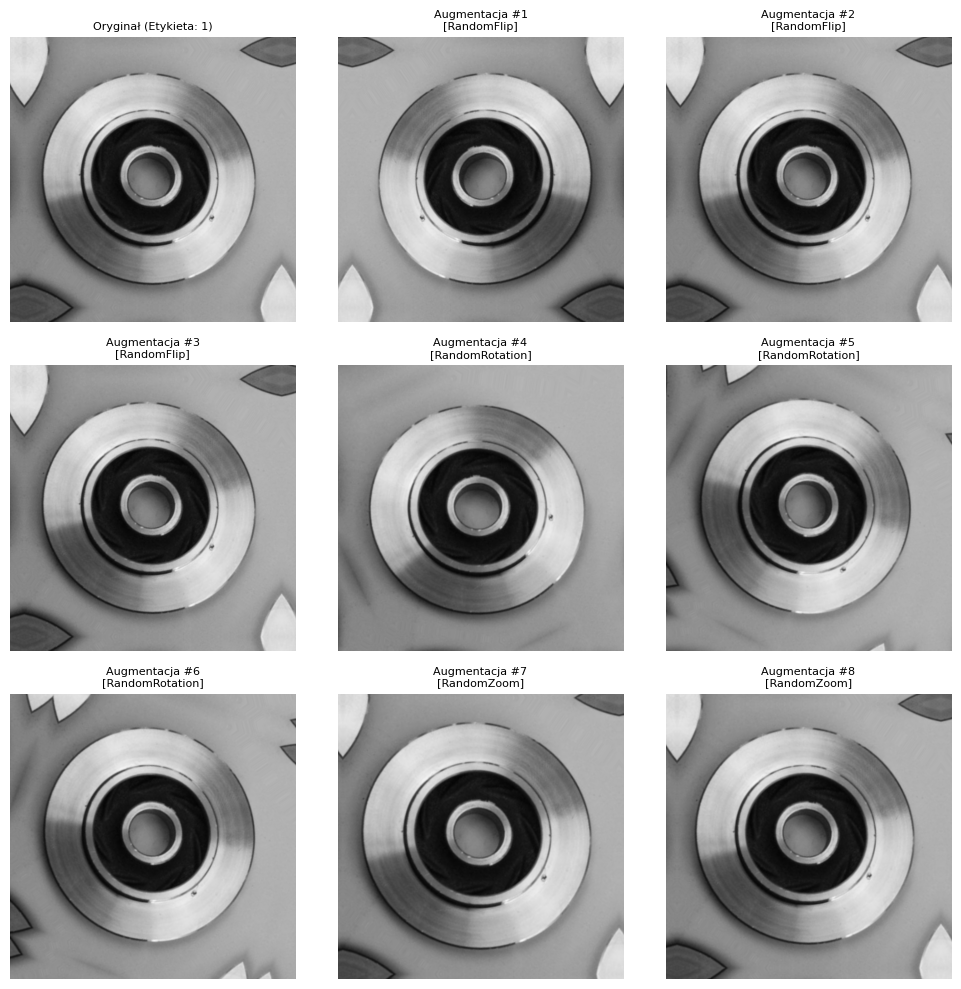

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# Pobranie jednej paczki danych z datasetu
for images, labels in augmented_train_dataset.take(1):
    first_image = images[0]
    label_val = labels[0].numpy()

    # Definicja pojedynczych warstw w celu pokazania konkretnych transformacji
    flip_layer = layers.RandomFlip("horizontal")
    rotation_layer = layers.RandomRotation(0.1)
    zoom_layer = layers.RandomZoom(0.2)

    # Zmniejszono wymiary figury (z 12x12 na 8x8)
    plt.figure(figsize=(10, 10))

    # Wyświetlenie 9 kafelków w siatce 3x3 z jawnym podaniem nazwy transformacji
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        if i == 0:
            # Obraz oryginalny
            display_image = first_image
            title_text = f"Oryginał (Etykieta: {label_val})"
        elif i in [1, 2, 3]:
            # Tylko RandomFlip
            display_image = flip_layer(tf.expand_dims(first_image, 0), training=True)[0]
            title_text = f"Augmentacja #{i}\n[RandomFlip]"
        elif i in [4, 5, 6]:
            # Tylko RandomRotation
            display_image = rotation_layer(tf.expand_dims(first_image, 0), training=True)[0]
            title_text = f"Augmentacja #{i}\n[RandomRotation]"
        else:
            # Tylko RandomZoom
            display_image = zoom_layer(tf.expand_dims(first_image, 0), training=True)[0]
            title_text = f"Augmentacja #{i}\n[RandomZoom]"

        plt.imshow(display_image.numpy().astype("uint8"))
        plt.title(title_text, fontsize=8)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

**Definiujemy warstwę odpowiadającą za augmentację**

In [ ]:
# import tensorflow as tf
# from tensorflow.keras import layers

# # Definicja warstw augmentacji danych jako osobnego obiektu Sequential
# data_augmentation_layers = tf.keras.Sequential([
#     layers.RandomFlip("horizontal"),
#     layers.RandomRotation(0.1),
#     layers.RandomZoom(0.2),
# ])

Model trenowany na podstawie augmentowanych zdjęć widzi tylko raz jedno zdjęcie. Niemniej, zdjęcia które widzi są mocno ze sobą skorelowane dlatego, że pochodzą z organicznej ilości oryginalnych zdjęć. Innymi słowy, nie tworzymy nowych informacji ale miksujemy już istniejące. Dlatego też, augmentacja może nie wystarczyć aby pozbyć się nadmiernego dopasowania się modelu do danych treningowych. W związku z tym dodajemy warstwę Dropout przed klasyfikatorem.

In [ ]:
import keras
from keras import layers

# Ustawienie ziarna losowości przed budową modelu
keras.utils.set_random_seed(42)

#Model oczekuje zdjęć RGB w rozmiarze 512 x 512
inputs = keras.Input(shape = (512,512,3))

# Rescales inputs to the [0, 1] range by dividing them by 255
x = layers.Rescaling(1.0 / 255)(inputs)
x = data_augmentation_layers(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
# Flattens the 3D activations with shape (height, width, 512) into 1D
# activations with shape (512,) by averaging them over spatial
# dimensions
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 510, 510, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 255, 255, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 253, 253, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 126, 126, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 124, 124, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,569,089 (5.99 MB)

 Trainable params: 1,569,089 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

**Ustalanie hiperparametrów**

Jako funkcję straty wybieramy "binary_crossentropy" ze względu na binarność klasyfikacji. Optimizerem będzie "adam".

In [ ]:
import tensorflow as tf

# Usunięto tf.keras.metrics.F1Score, ponieważ dla wyjścia binarnego 1D generuje on błąd wymiarów.
# F1-score będzie poprawnie wyliczany ręcznie i wizualizowany po zakończeniu treningu.
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)
print("Model został pomyślnie skompilowany ze zgodnymi metrykami.")

Model został pomyślnie skompilowany ze zgodnymi metrykami.


Trenowanie modelu

In [ ]:
# Połączenie EarlyStopping oraz ModelCheckpoint na jednej liście
callbacks = [
    # keras.callbacks.EarlyStopping(
    #     monitor="val_loss",
    #     patience=7,
    #     restore_best_weights=True
    # ),
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_extended.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

# Uruchomienie procesu uczenia
history_convnet_extended = model.fit(
    augmented_train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.6011 - loss: 0.6835 - precision: 0.6011 - recall: 1.0000 - val_accuracy: 0.6000 - val_loss: 0.6692 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.6011 - loss: 0.6610 - precision: 0.6011 - recall: 1.0000 - val_accuracy: 0.6000 - val_loss: 0.6575 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.6165 - loss: 0.6362 - precision: 0.6110 - recall: 0.9963 - val_accuracy: 0.6000 - val_loss: 0.6582 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.6242 - loss: 0.6384 - precision: 0.6163 - recall: 0.9927 - val_accuracy: 0.6000 - val_loss: 0.6829 - val_precision: 0.6000 - val_recall: 1.0000
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.6516 - loss: 0.6100 - precision: 0.6430 - recall: 0.9452 - val_accuracy: 0.6000 - val_loss: 0.6617 - val

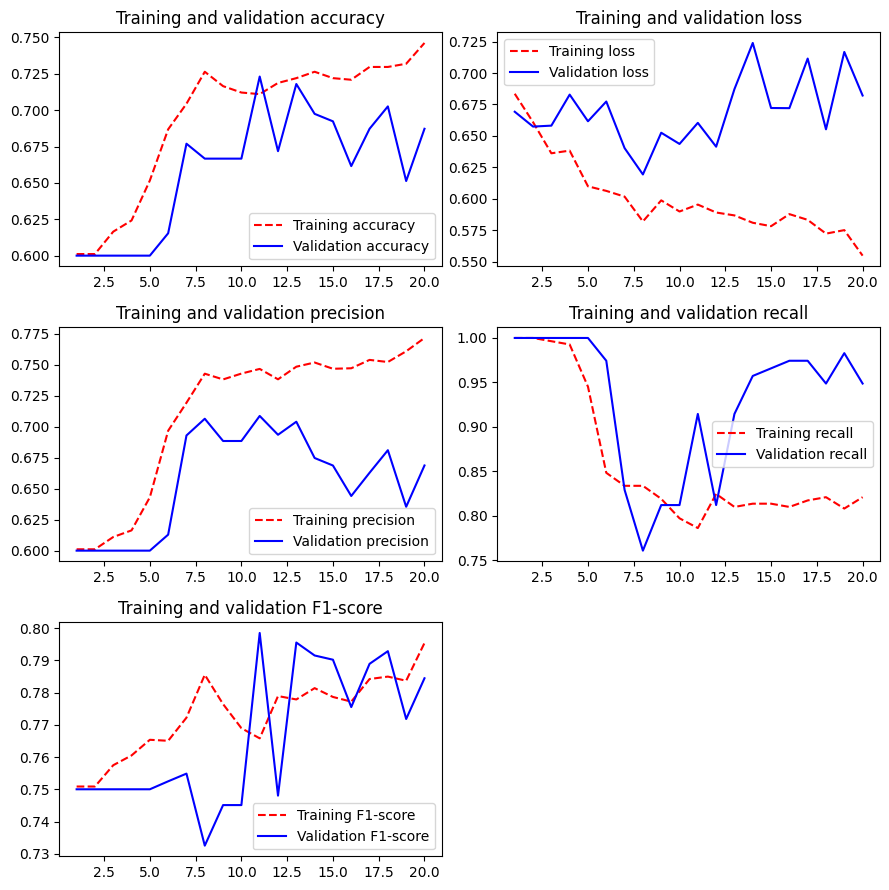

In [ ]:
import matplotlib.pyplot as plt

history = history_convnet_extended



# Określenie liczby epok
epochs = range(1, len(history.history["loss"]) + 1)

# Pobranie podstawowych metryk
acc = history.history.get("accuracy", history.history.get("acc"))
val_acc = history.history.get("val_accuracy", history.history.get("val_acc"))

loss = history.history["loss"]
val_loss = history.history["val_loss"]

precision = history.history["precision"]
val_precision = history.history["val_precision"]

recall = history.history["recall"]
val_recall = history.history["val_recall"]

# Pobranie lub wyliczenie F1-score (dla treningu i walidacji)
if "f1_score" in history.history:
    f1 = history.history["f1_score"]
    val_f1 = history.history["val_f1_score"]
else:
    f1 = 2 * (np.array(precision) * np.array(recall)) / (np.array(precision) + np.array(recall) + 1e-7)
    val_f1 = 2 * (np.array(val_precision) * np.array(val_recall)) / (np.array(val_precision) + np.array(val_recall) + 1e-7)

# Tworzenie figury w układzie 3 wiersze x 2 kolumny (miejsce na 6 wykresów)
fig, axes = plt.subplots(3, 2, figsize=(9, 9))

# --- 1. Wykres Accuracy (wiersz 1, kolumna 1) ---
if acc:
    axes[0, 0].plot(epochs, acc, "r--", label="Training accuracy")
    axes[0, 0].plot(epochs, val_acc, "b", label="Validation accuracy")
    axes[0, 0].set_title("Training and validation accuracy")
    axes[0, 0].legend()

# --- 2. Wykres Loss (wiersz 1, kolumna 2) ---
axes[0, 1].plot(epochs, loss, "r--", label="Training loss")
axes[0, 1].plot(epochs, val_loss, "b", label="Validation loss")
axes[0, 1].set_title("Training and validation loss")
axes[0, 1].legend()

# --- 3. Wykres Precision (wiersz 2, kolumna 1) ---
axes[1, 0].plot(epochs, precision, "r--", label="Training precision")
axes[1, 0].plot(epochs, val_precision, "b", label="Validation precision")
axes[1, 0].set_title("Training and validation precision")
axes[1, 0].legend()

# --- 4. Wykres Recall (wiersz 2, kolumna 2) ---
axes[1, 1].plot(epochs, recall, "r--", label="Training recall")
axes[1, 1].plot(epochs, val_recall, "b", label="Validation recall")
axes[1, 1].set_title("Training and validation recall")
axes[1, 1].legend()

# --- 5. Wykres F1-score (wiersz 3, kolumna 1) ---
axes[2, 0].plot(epochs, f1, "r--", label="Training F1-score")
axes[2, 0].plot(epochs, val_f1, "b", label="Validation F1-score")
axes[2, 0].set_title("Training and validation F1-score")
axes[2, 0].legend()

# --- Ukrycie pustego 6. pola (wiersz 3, kolumna 2) ---
axes[2, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
test_model_convnet_extended = keras.models.load_model("convnet_extended.keras")
test_loss, test_acc, test_prec, test_rec = test_model_convnet_extended.evaluate(test_dataset)

print(f"Test accuracy: {test_acc*100:.1f}%")
print(f"Test precision: {test_prec*100:.1f}%")
print(f"Test recall: {test_rec*100:.1f}%")
print(f"Test F1-score: {2 * (test_prec * test_rec) / (test_prec + test_rec)*100:.1F}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.6923 - loss: 0.5665 - precision: 0.7080 - recall: 0.8291
Test accuracy: 69.2%
Test precision: 70.8%
Test recall: 82.9%
Test F1-score: 76.4%


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step


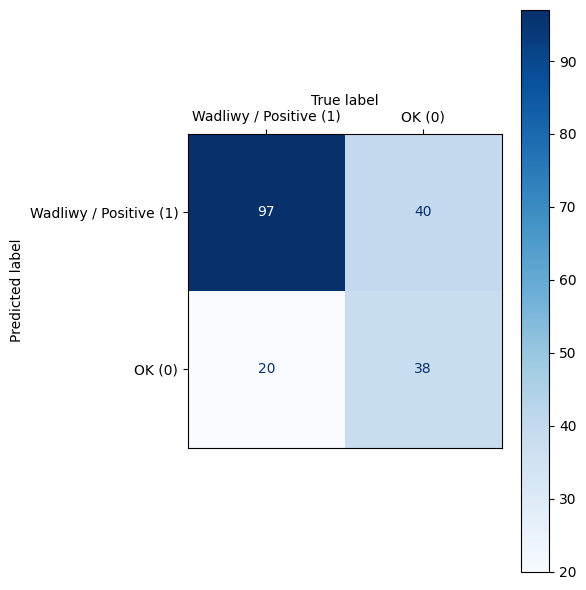

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

test_model = test_model_convnet_extended

# Zebranie wszystkich prawdziwych etykiet i predykcji ze zbioru testowego
y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = test_model.predict(test_dataset)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

# 1. Kolejność labels=[1, 0] umieszcza klasę pozytywną (Wadliwy) w 1. wierszu i 1. kolumnie
# 2. Transpozycja (.T) zamienia osie: wiersze = Predicted, kolumny = True
cm = confusion_matrix(y_true, y_pred, labels=[1, 0]).T

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Wadliwy / Positive (1)", "OK (0)"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)

# Zaktualizowanie opisów osi po transpozycji
ax.set_ylabel("Predicted label")
ax.set_xlabel("True label")

# Przeniesienie etykiety "True label" oraz nazw kolumn na górę wykresu
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.tight_layout()
plt.show()

**Uczenie transferowe**

Keras oferuje modele z rodziny ResNet takie jak ResNet50, ResNet101, ResNet152

Użycie ResNet:
-wymiary tensora wejściowego - domyślny rozmiar (224, 224, 3) (wysokość, szerokość, 3 kanały kolorów). ResNet akceptuje dowolną rozdzielczość nie mniejszą niż 32 x 32 w tym obrazy o wymiarach (512, 512, 3)

-format i zakres wartości pikseli - W odróżnieniu od dotychczasowych modeli, które używały layers.Rescaling(1.0 / 255) do sprowadzenia pikseli do przedziału [0, 1], ResNet nie oczekuje wartości z przedziału [0, 1]. Model, przed wstępną obróbką danych, oczekuje Oczekuje liczby z przedziału [0, 255] w formacie RGB. Dedykowana funkcja preprocess_input zamienia kolejność kanałów z RGB na BGR oraz odejmuje od każdego kanału średnią ze zbioru ImageNet (centrowanie wokół zera, bez dzielenia przez 255



Ładujemy ResNet50 wytrenowany na ImageNet (1,4 mln zdjęć), bez ostatniej warstwy klasyfikującej (include_top=False). Bazę zamrażamy — nie chcemy psuć wyuczonych cech. Dodajemy własną „głowę" pod nasz problem.

In [ ]:
import keras
from keras import layers
from keras.applications import ResNet50
from keras.applications.resnet import preprocess_input

# 1. Wczytanie bazy ResNet50 bez górnej warstwy klasyfikacyjnej
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(512, 512, 3)
)
base_model.trainable = False  # Zamrożenie wag na start (Feature Extraction)

# 2. Budowa modelu z Twoimi danymi (512x512x3, wartości [0, 255])
inputs = keras.Input(shape=(512, 512, 3))
x = data_augmentation_layers(inputs)
x = preprocess_input(x)  # <-- Kluczowy krok zamiast Rescaling(1./255)!
x = base_model(x, training=False)

# 3. Twoja głowica klasyfikacyjna
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

resnet_model = keras.Model(inputs=inputs, outputs=outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
resnet_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 512, 512,  │          0 │ input_layer_4[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 512, 512)  │          0 │ sequential[1][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 512, 512)  │          0 │ sequential[1][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 512, 512)  │          0 │ sequential[1][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 512, 512,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512, 512,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 16, 16,    │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │      2,049 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resnet_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


**Trening (feature extraction)**

In [ ]:
# Połączenie EarlyStopping oraz ModelCheckpoint na jednej liście
callbacks = [
    # keras.callbacks.EarlyStopping(
    #     monitor="val_loss",
    #     patience=5,
    #     restore_best_weights=True
    # ),
    keras.callbacks.ModelCheckpoint(
        filepath="resnet50_frozen.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

# Uruchomienie procesu uczenia
history_resnet = resnet_model.fit(
    augmented_train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.6835 - loss: 0.6011 - precision: 0.7113 - recall: 0.7971 - val_accuracy: 0.7436 - val_loss: 0.5229 - val_precision: 0.8317 - val_recall: 0.7179
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.7560 - loss: 0.4807 - precision: 0.7826 - recall: 0.8227 - val_accuracy: 0.8103 - val_loss: 0.4264 - val_precision: 0.9255 - val_recall: 0.7436
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8066 - loss: 0.4188 - precision: 0.8295 - recall: 0.8537 - val_accuracy: 0.8513 - val_loss: 0.3718 - val_precision: 0.9074 - val_recall: 0.8376
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8220 - loss: 0.3933 - precision: 0.8456 - recall: 0.8611 - val_accuracy: 0.8615 - val_loss: 0.3469 - val_precision: 0.9412 - val_recall: 0.8205
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8582 - loss: 0.3464 - precision: 0.8870 - recall: 0.8757 - val_accuracy: 0.8769 - val_loss: 0.3175 - va

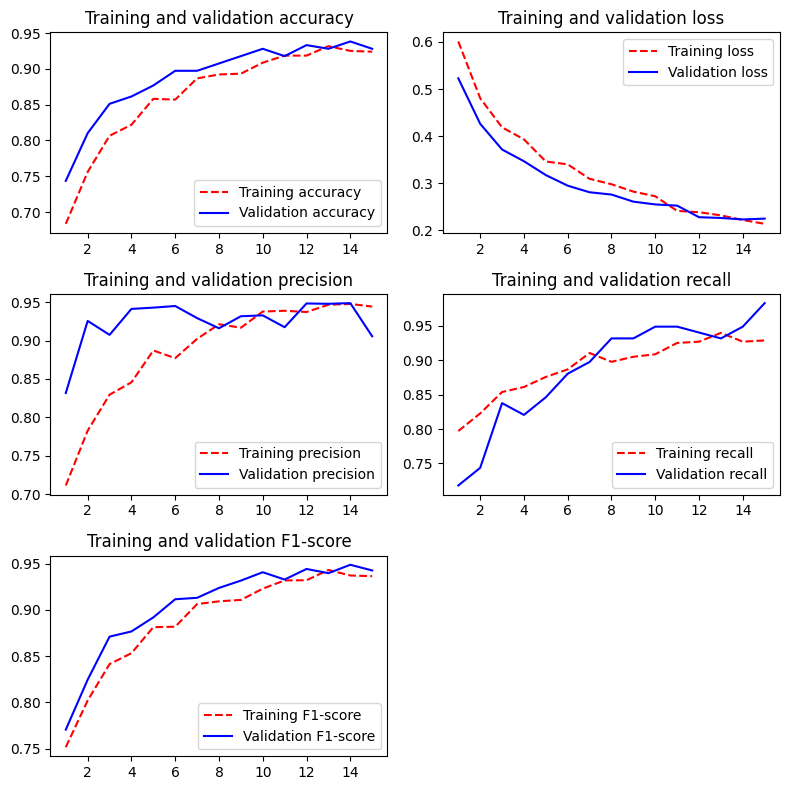

In [ ]:
history = history_resnet

# Określenie liczby epok
epochs = range(1, len(history.history["loss"]) + 1)

# Pobranie podstawowych metryk
acc = history.history.get("accuracy", history.history.get("acc"))
val_acc = history.history.get("val_accuracy", history.history.get("val_acc"))

loss = history.history["loss"]
val_loss = history.history["val_loss"]

precision = history.history["precision"]
val_precision = history.history["val_precision"]

recall = history.history["recall"]
val_recall = history.history["val_recall"]

# Pobranie lub wyliczenie F1-score (dla treningu i walidacji)
if "f1_score" in history.history:
    f1 = history.history["f1_score"]
    val_f1 = history.history["val_f1_score"]
else:
    f1 = 2 * (np.array(precision) * np.array(recall)) / (np.array(precision) + np.array(recall) + 1e-7)
    val_f1 = 2 * (np.array(val_precision) * np.array(val_recall)) / (np.array(val_precision) + np.array(val_recall) + 1e-7)

# Tworzenie figury w układzie 3 wiersze x 2 kolumny (miejsce na 6 wykresów)
fig, axes = plt.subplots(3, 2, figsize=(8, 8))

# --- 1. Wykres Accuracy (wiersz 1, kolumna 1) ---
if acc:
    axes[0, 0].plot(epochs, acc, "r--", label="Training accuracy")
    axes[0, 0].plot(epochs, val_acc, "b", label="Validation accuracy")
    axes[0, 0].set_title("Training and validation accuracy")
    axes[0, 0].legend()

# --- 2. Wykres Loss (wiersz 1, kolumna 2) ---
axes[0, 1].plot(epochs, loss, "r--", label="Training loss")
axes[0, 1].plot(epochs, val_loss, "b", label="Validation loss")
axes[0, 1].set_title("Training and validation loss")
axes[0, 1].legend()

# --- 3. Wykres Precision (wiersz 2, kolumna 1) ---
axes[1, 0].plot(epochs, precision, "r--", label="Training precision")
axes[1, 0].plot(epochs, val_precision, "b", label="Validation precision")
axes[1, 0].set_title("Training and validation precision")
axes[1, 0].legend()

# --- 4. Wykres Recall (wiersz 2, kolumna 2) ---
axes[1, 1].plot(epochs, recall, "r--", label="Training recall")
axes[1, 1].plot(epochs, val_recall, "b", label="Validation recall")
axes[1, 1].set_title("Training and validation recall")
axes[1, 1].legend()

# --- 5. Wykres F1-score (wiersz 3, kolumna 1) ---
axes[2, 0].plot(epochs, f1, "r--", label="Training F1-score")
axes[2, 0].plot(epochs, val_f1, "b", label="Validation F1-score")
axes[2, 0].set_title("Training and validation F1-score")
axes[2, 0].legend()

# --- Ukrycie pustego 6. pola (wiersz 3, kolumna 2) ---
axes[2, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
test_model_resnet50_frozen = keras.models.load_model("resnet50_frozen.keras")
test_loss, test_acc, test_prec, test_rec = test_model_resnet50_frozen.evaluate(test_dataset)

print(f"Test accuracy: {test_acc*100:.1f}%")
print(f"Test precision: {test_prec*100:.1f}%")
print(f"Test recall: {test_rec*100:.1f}%")
print(f"Test F1-score: {2 * (test_prec * test_rec) / (test_prec + test_rec)*100:.1F}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 304ms/step - accuracy: 0.9282 - loss: 0.2341 - precision: 0.9328 - recall: 0.9487
Test accuracy: 92.8%
Test precision: 93.3%
Test recall: 94.9%
Test F1-score: 94.1%


13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 463ms/step


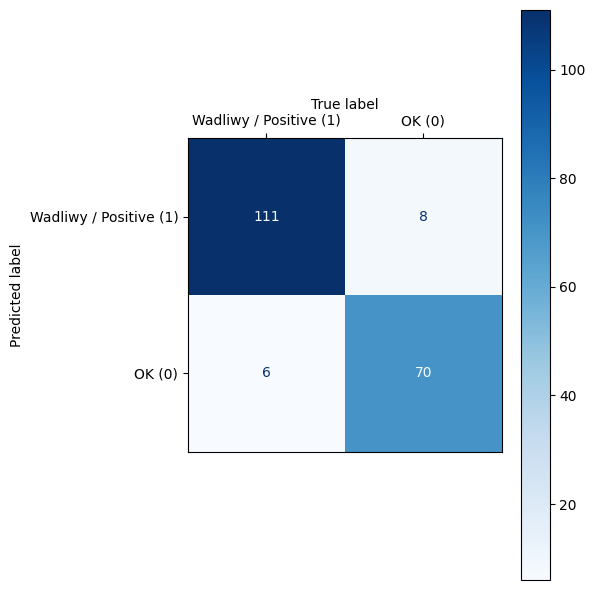

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

test_model = test_model_resnet50_frozen

# Zebranie wszystkich prawdziwych etykiet i predykcji ze zbioru testowego
y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = test_model.predict(test_dataset)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

# 1. Kolejność labels=[1, 0] umieszcza klasę pozytywną (Wadliwy) w 1. wierszu i 1. kolumnie
# 2. Transpozycja (.T) zamienia osie: wiersze = Predicted, kolumny = True
cm = confusion_matrix(y_true, y_pred, labels=[1, 0]).T

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Wadliwy / Positive (1)", "OK (0)"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)

# Zaktualizowanie opisów osi po transpozycji
ax.set_ylabel("Predicted label")
ax.set_xlabel("True label")

# Przeniesienie etykiety "True label" oraz nazw kolumn na górę wykresu
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.tight_layout()
plt.show()

**Douczanie modelu (Fine-tuning)**

Możemy odmrozić górne warstwy bazy i douczyć je do naszego problemu. Kluczowa zasada: bardzo niska szybkość uczenia, żeby nie zniszczyć wyuczonych wag.

In [ ]:
base_model.trainable = True
# zamrażamy wszystko poza ostatnimi ~30 warstwami
for warstwa in base_model.layers[:-30]:
    warstwa.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),   # bardzo niska LR!
              loss="binary_crossentropy",
              metrics=[
                tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                tf.keras.metrics.Precision(name="precision"),
                tf.keras.metrics.Recall(name="recall")
    ])

# Połączenie EarlyStopping oraz ModelCheckpoint na jednej liście
callbacks = [
    # keras.callbacks.EarlyStopping(
    #     monitor="val_loss",
    #     patience=5,
    #     restore_best_weights=True
    # ),
    keras.callbacks.ModelCheckpoint(
        filepath="resnet50_ft.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

history_resnet50_ft = model.fit(
    augmented_train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=callbacks,
    verbose=1)


Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.7462 - loss: 0.5451 - precision: 0.7660 - recall: 0.8318 - val_accuracy: 0.6872 - val_loss: 0.6786 - val_precision: 0.6687 - val_recall: 0.9487
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.7473 - loss: 0.5448 - precision: 0.7682 - recall: 0.8300 - val_accuracy: 0.6872 - val_loss: 0.6754 - val_precision: 0.6687 - val_recall: 0.9487
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.7473 - loss: 0.5475 - precision: 0.7691 - recall: 0.8282 - val_accuracy: 0.6923 - val_loss: 0.6727 - val_precision: 0.6727 - val_recall: 0.9487
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.7418 - loss: 0.5472 - precision: 0.7662 - recall: 0.8208 - val_accuracy: 0.6923 - val_loss: 0.6724 - val_precision: 0.6727 - val_recall: 0.9487
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.7451 - loss: 0.5416 - precision: 0.7730 - recall: 0.8154 - val_accuracy: 0.6923 - val_loss: 0.6755 - val

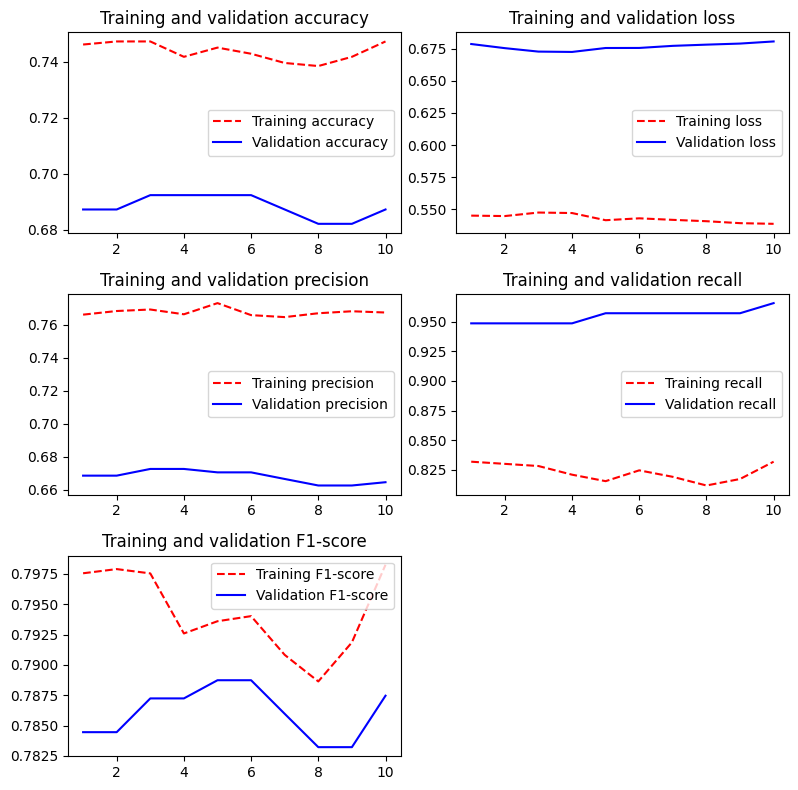

In [ ]:
history = history_resnet50_ft

# Określenie liczby epok
epochs = range(1, len(history.history["loss"]) + 1)

# Pobranie podstawowych metryk
acc = history.history.get("accuracy", history.history.get("acc"))
val_acc = history.history.get("val_accuracy", history.history.get("val_acc"))

loss = history.history["loss"]
val_loss = history.history["val_loss"]

precision = history.history["precision"]
val_precision = history.history["val_precision"]

recall = history.history["recall"]
val_recall = history.history["val_recall"]

# Pobranie lub wyliczenie F1-score (dla treningu i walidacji)
if "f1_score" in history.history:
    f1 = history.history["f1_score"]
    val_f1 = history.history["val_f1_score"]
else:
    f1 = 2 * (np.array(precision) * np.array(recall)) / (np.array(precision) + np.array(recall) + 1e-7)
    val_f1 = 2 * (np.array(val_precision) * np.array(val_recall)) / (np.array(val_precision) + np.array(val_recall) + 1e-7)

# Tworzenie figury w układzie 3 wiersze x 2 kolumny (miejsce na 6 wykresów)
fig, axes = plt.subplots(3, 2, figsize=(8, 8))

# --- 1. Wykres Accuracy (wiersz 1, kolumna 1) ---
if acc:
    axes[0, 0].plot(epochs, acc, "r--", label="Training accuracy")
    axes[0, 0].plot(epochs, val_acc, "b", label="Validation accuracy")
    axes[0, 0].set_title("Training and validation accuracy")
    axes[0, 0].legend()

# --- 2. Wykres Loss (wiersz 1, kolumna 2) ---
axes[0, 1].plot(epochs, loss, "r--", label="Training loss")
axes[0, 1].plot(epochs, val_loss, "b", label="Validation loss")
axes[0, 1].set_title("Training and validation loss")
axes[0, 1].legend()

# --- 3. Wykres Precision (wiersz 2, kolumna 1) ---
axes[1, 0].plot(epochs, precision, "r--", label="Training precision")
axes[1, 0].plot(epochs, val_precision, "b", label="Validation precision")
axes[1, 0].set_title("Training and validation precision")
axes[1, 0].legend()

# --- 4. Wykres Recall (wiersz 2, kolumna 2) ---
axes[1, 1].plot(epochs, recall, "r--", label="Training recall")
axes[1, 1].plot(epochs, val_recall, "b", label="Validation recall")
axes[1, 1].set_title("Training and validation recall")
axes[1, 1].legend()

# --- 5. Wykres F1-score (wiersz 3, kolumna 1) ---
axes[2, 0].plot(epochs, f1, "r--", label="Training F1-score")
axes[2, 0].plot(epochs, val_f1, "b", label="Validation F1-score")
axes[2, 0].set_title("Training and validation F1-score")
axes[2, 0].legend()

# --- Ukrycie pustego 6. pola (wiersz 3, kolumna 2) ---
axes[2, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
test_model_resnet50_ft = keras.models.load_model("resnet50_ft.keras")
test_loss, test_acc, test_prec, test_rec = test_model_resnet50_ft.evaluate(test_dataset)

print(f"Test accuracy: {test_acc*100:.1f}%")
print(f"Test precision: {test_prec*100:.1f}%")
print(f"Test recall: {test_rec*100:.1f}%")
print(f"Test F1-score: {2 * (test_prec * test_rec) / (test_prec + test_rec)*100:.1F}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.7231 - loss: 0.5777 - precision: 0.6864 - recall: 0.9915
Test accuracy: 72.3%
Test precision: 68.6%
Test recall: 99.1%
Test F1-score: 81.1%


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step


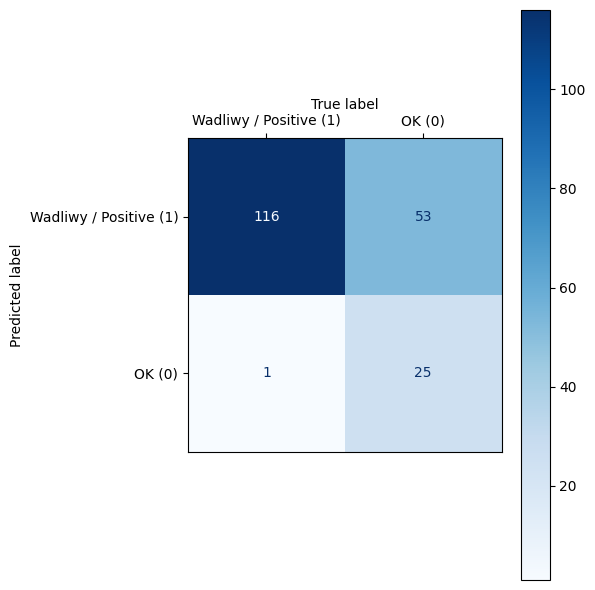

In [ ]:
test_model = test_model_resnet50_ft

# Zebranie wszystkich prawdziwych etykiet i predykcji ze zbioru testowego
y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = test_model.predict(test_dataset)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

# 1. Kolejność labels=[1, 0] umieszcza klasę pozytywną (Wadliwy) w 1. wierszu i 1. kolumnie
# 2. Transpozycja (.T) zamienia osie: wiersze = Predicted, kolumny = True
cm = confusion_matrix(y_true, y_pred, labels=[1, 0]).T

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Wadliwy / Positive (1)", "OK (0)"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)

# Zaktualizowanie opisów osi po transpozycji
ax.set_ylabel("Predicted label")
ax.set_xlabel("True label")

# Przeniesienie etykiety "True label" oraz nazw kolumn na górę wykresu
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.tight_layout()
plt.show()

**Detekcja anomalii**

W detekcji anomalii zmieniamy filozofię: model uczy się wyłącznie na poprawnych odlewach. Do tego zadania najlepiej sprawdza się Autoenkoder Splotowy (Convolutional Autoencoder). Jego zadaniem jest „nauczenie się” kompresji, a następnie idealnej rekonstrukcji obrazu poprawnego odlewu. Gdy podamy mu odlew wadliwy (którego model nigdy wcześniej nie widział), autoenkoder nie będzie potrafił go poprawnie zrekonstruować, co spowoduje wysoki błąd rekonstrukcji (MSE). Przekroczenie ustalonego progu błędu oznacza wykrycie anomali / wady

**Przygotowanie danych**

Do trenowania autoenkodera bierzemy wyłącznie próbki z klasy ok ze zbioru treningowego:

In [ ]:
import tensorflow as tf
import keras
from keras import layers, Model
import numpy as np
import matplotlib.pyplot as plt

# Wyselekcjonowanie wyłącznie poprawnych ścieżek (etykieta 0) ze zbioru treningowego
train_ok_paths = [str(p) for p, l in zip(train_paths, train_labels) if l == 0]
print(f"Liczba poprawnych próbek do treningu autoenkodera: {len(train_ok_paths)}")

# Funkcja wczytująca i skalująca obraz do zakresu [0, 1] (wejście = wyjście)
def load_for_autoencoder(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, [512, 512])
    image = image / 255.0
    return image, image

# Tworzenie tf.data.Dataset dla autoenkodera
autoencoder_train_ds = tf.data.Dataset.from_tensor_slices((train_ok_paths, train_ok_paths))
autoencoder_train_ds = autoencoder_train_ds.map(
    lambda x, y: (load_for_autoencoder(x)[0], load_for_autoencoder(y)[1]),
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 16
autoencoder_train_ds = autoencoder_train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Liczba poprawnych próbek do treningu autoenkodera: 363


Z punktu widzenia rzetelnej metodologii i stworzenia obiektywnego porównania modeli w projekcie, autoenkoder powinien uczyć się wyłącznie na poprawnych próbkach ze zbioru treningowego (363 sztuki), a pozostałe poprawne próbki ze zbiorów walidacyjnego i testowego powinny zostać nienaruszone. Aby udowodnić, że model detekcji anomalii działa poprawnie, musisz go przetestować na zupełnie nowych, niewidzianych wcześniej danych obu klas: Na poprawnych elementach ze zbioru testowego sprawdzasz, czy model nie generuje zbyt wielu fałszywych alarmów (False Positives – odrzucanie dobrego odlewu) oraz Na wadliwych elementach ze zbioru testowego sprawdzasz, czy model skutecznie wykrywa anomalie (True Positives).
Gdybyś do treningu autoenkodera zużył absolutnie wszystkie 519 próbek ok, straciłbyś czysty zbiór testowy dla poprawnych elementów.

Wnioski:
Trening autoenkodera: Użyj wyłącznie train_ok_paths (363 próbki).

Strojenie progu błędu (Threshold): Próg, powyżej którego odlew uznajemy za wadliwy, wyznacz na zbiorze walidacyjnym (np. na tych 78 poprawnych i odpowiadających im wadliwych próbkach walidacyjnych)

Finalny test: Ostateczną skuteczność detektora anomalii zmierz na niezmienionym test_dataset

**Budowa Architektury Autoenkodera Splotowego**

In [ ]:
keras.utils.set_random_seed(42)

# Enkoder
input_img = keras.Input(shape=(512, 512, 3))
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(input_img)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
encoded = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)

# Dekodera
x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(encoded)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.UpSampling2D((2, 2))(x)
decoded = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

autoencoder = Model(input_img, decoded, name="conv_autoencoder")
autoencoder.summary()

Model: "conv_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 512, 512, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 256, 256, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 128, 128, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 256, 256, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 512, 512, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 512, 512, 3)    │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,355 (1.21 MB)

 Trainable params: 316,355 (1.21 MB)

 Non-trainable params: 0 (0.00 B)

**Kompilacja i Trening (tylko na danych OK)**

Model optymalizujemy funkcją straty MSE (Mean Squared Error), ponieważ chcemy minimalizować różnicę pikseli między obrazem oryginalnym a zrekonstruowanym.

In [ ]:
autoencoder.compile(optimizer="adam", loss="mse")

callbacks_ae = [
    keras.callbacks.EarlyStopping(monitor="loss", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(filepath="autoencoder_ok.keras", save_best_only=True, monitor="loss")
]

# Trening odbywa się WYŁĄCZNIE na poprawnych odlewach!
history_ae = autoencoder.fit(
    autoencoder_train_ds,
    epochs=20,
    callbacks=callbacks_ae
)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 442ms/step - loss: 0.0362
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 436ms/step - loss: 0.0047
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 426ms/step - loss: 0.0021
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 419ms/step - loss: 0.0013
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 416ms/step - loss: 0.0013
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 412ms/step - loss: 8.7546e-04
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 413ms/step - loss: 7.8946e-04
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 415ms/step - loss: 8.0133e-04
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 423ms/step - loss: 6.0783e-04
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 423ms/step - loss: 6.4567e-04
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 425ms/step - loss: 6.5958e-04
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 424ms/step - loss: 5.1142e-04
Epoch 13/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 424ms/step - loss: 4.6057e-04
Epoch 14/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 419ms/step - loss: 4.1607e-04
Epoch 1

**Funkcja straty**

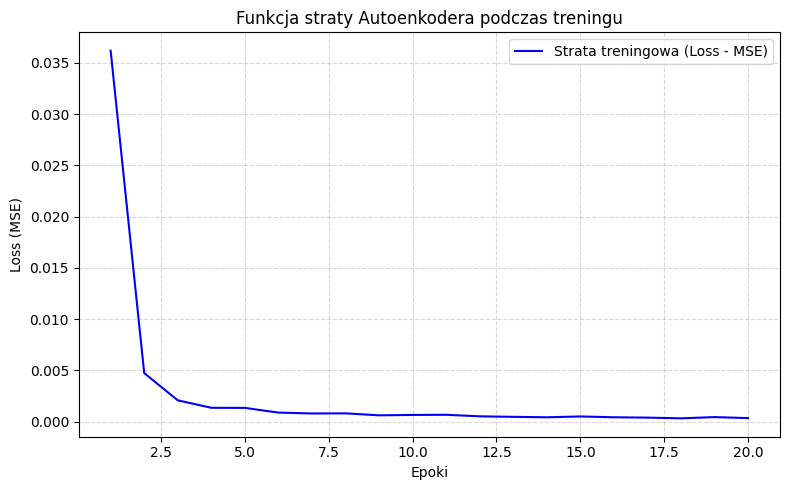

In [ ]:
import matplotlib.pyplot as plt

history = history_ae

# Określenie liczby epok
epochs = range(1, len(history.history["loss"]) + 1)

# Pobranie wartości funkcji straty (MSE)
loss = history.history["loss"]

# Tworzenie wykresu
plt.figure(figsize=(8, 5))
plt.plot(epochs, loss, "b-", label="Strata treningowa (Loss - MSE)")
plt.title("Funkcja straty Autoenkodera podczas treningu")
plt.xlabel("Epoki")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Szybki spadek na początku (Epoki 1–3)
Co się dzieje: Widzimy gwałtowny spadek błędu z wartości ok. 0.036 do poniżej 0.005 już w pierwszych trzech epokach.

Interpretacja: Model bardzo szybko uczy się ogólnego kształtu i jasności odlewów (podstawowych cech wizualnych poprawnych wirników). Jest to całkowicie naturalne i pożądane zachowanie sieci neuronowej.

Płaskowyż i stabilizacja (Od ok. 5. epoki)
Co się dzieje: Linia staje się niemal płaska, powoli i stabilnie opadając w kierunku zera (osiągając wartości rzędu 0.0005 pod koniec treningu).

Interpretacja: Model osiągnął zbieżność. Enkoder i dekoder nauczyły się optymalnie kompresować i rekonstrukceć poprawne próbki. Brak gwałtownych skoków czy oscylacji świadczy o tym, że współczynnik uczenia (learning rate) jest odpowiednio dobrany, a proces treningowy jest stabilny.

Ocena jakości modelu pod kątem detekcji anomalii
Ponieważ wartość błędu MSE na koniec spadła bardzo nisko (blisko zera) i ustabilizowała się, oznacza to, że autoenkoder potrafi niemal idealnie zrekonstruować poprawne odlewy (OK).

To świetna wiadomość dla detekcji anomalii: zdrowe elementy będą miały ekstremalnie niski błąd rekonstrukcji, natomiast elementy wadliwe (których model nie zna) wygenerują znacznie wyższy błąd, co pozwoli na ich skuteczne odfiltrowanie po ustawieniu progu (threshold).

**Wizualizacja rekonstrukcji (Jak autoenkoder radzi sobie z błędem?)**

Możemy sprawdzić wizualnie, jak model rekonstruuje obraz poprawny oraz wadliwy

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


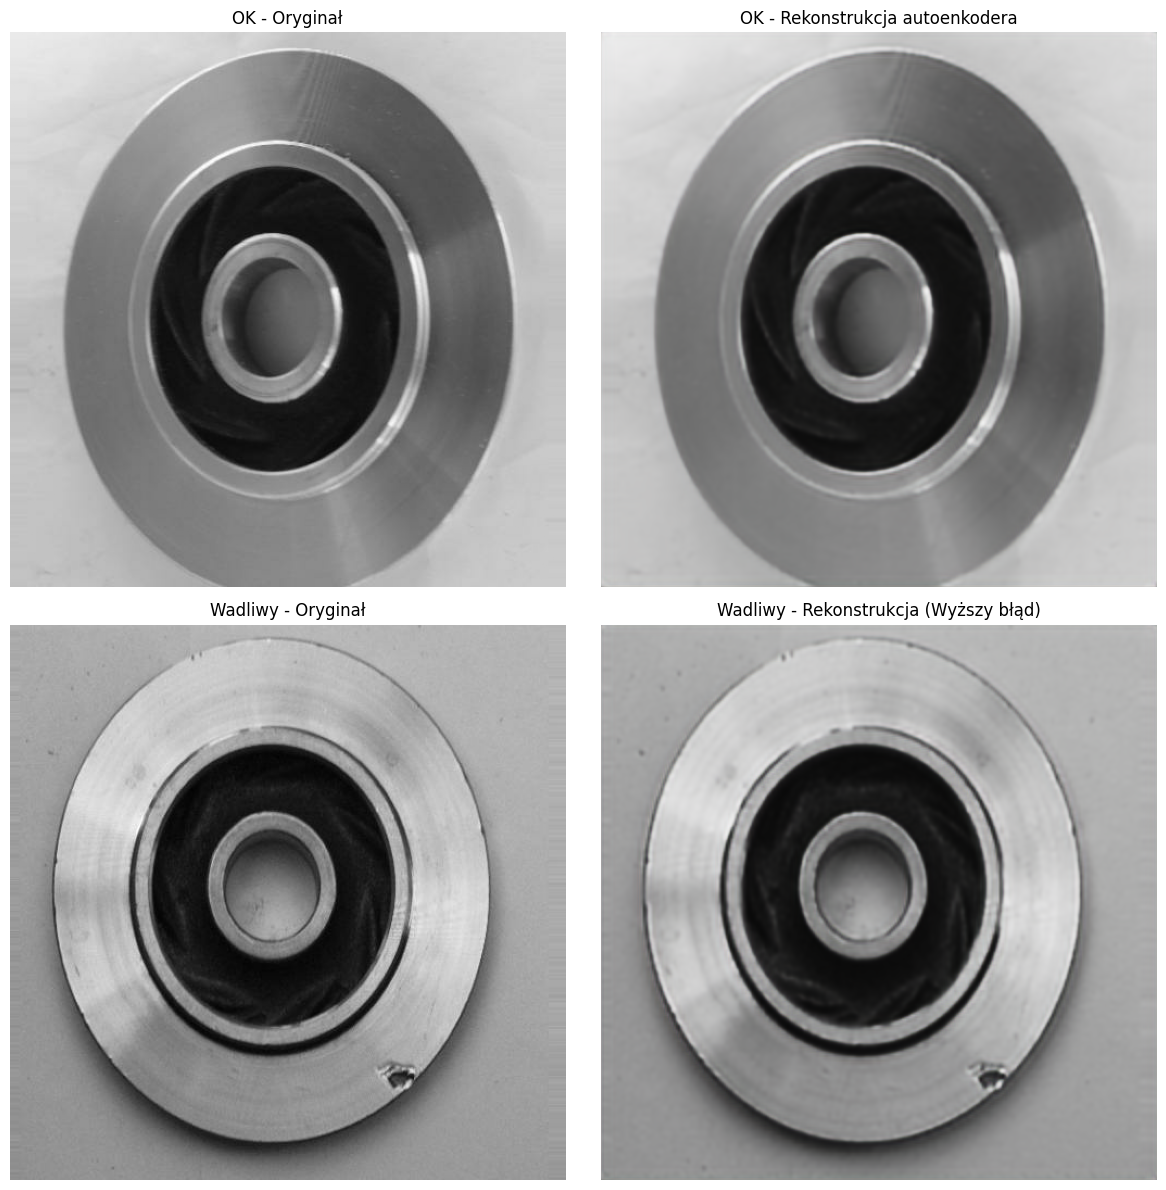

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Ustawienie ziarna losowości dla pełnej powtarzalności
tf.random.set_seed(42)

# Pobranie jednej pary próbek ze zbioru testowego (np. jeden OK i jeden Wadliwy)
test_ok_sample = next(iter(tf.data.Dataset.from_tensor_slices([str(p) for p, l in zip(test_paths, test_labels) if l == 0]).map(load_for_autoencoder).batch(1)))
test_def_sample = next(iter(tf.data.Dataset.from_tensor_slices([str(p) for p, l in zip(test_paths, test_labels) if l == 1]).map(load_for_autoencoder).batch(1)))

reconstructed_ok = autoencoder.predict(test_ok_sample[0])
reconstructed_def = autoencoder.predict(test_def_sample[0])

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
# Wiersz 1: Próbka OK (Oryginał vs Rekonstrukcja)
axes[0, 0].imshow(test_ok_sample[0][0])
axes[0, 0].set_title("OK - Oryginał")
axes[0, 0].axis("off")
axes[0, 1].imshow(reconstructed_ok[0])
axes[0, 1].set_title("OK - Rekonstrukcja autoenkodera")
axes[0, 1].axis("off")

# Wiersz 2: Próbka Wadliwa (Oryginał vs Rekonstrukcja – zauważ większy błąd/zamazanie w miejscu wady)
axes[1, 0].imshow(test_def_sample[0][0])
axes[1, 0].set_title("Wadliwy - Oryginał")
axes[1, 0].axis("off")
axes[1, 1].imshow(reconstructed_def[0])
axes[1, 1].set_title("Wadliwy - Rekonstrukcja (Wyższy błąd)")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Obliczenie MSE dla pojedynczego poprawnego elementu
mse_ok = np.mean(np.square(test_ok_sample[0][0] - reconstructed_ok[0]))

# Obliczenie MSE dla pojedynczego wadliwego elementu
mse_def = np.mean(np.square(test_def_sample[0][0] - reconstructed_def[0]))

print(f"Średni błąd kwadratowy (MSE) rekonstrukcji:")
print(f" - Element poprawny (OK):  {mse_ok:.6f}")
print(f" - Element wadliwy (DEF):  {mse_def:.6f}")

# Porównanie krotności błędu
ratio = mse_def / mse_ok
print(f"\nBłąd dla elementu wadliwego jest {ratio:.1f}x większy niż dla poprawnego!")

Średni błąd kwadratowy (MSE) rekonstrukcji:
 - Element poprawny (OK):  0.000149
 - Element wadliwy (DEF):  0.000336

Błąd dla elementu wadliwego jest 2.3x większy niż dla poprawnego!


Autoenkoder uczył się wyłącznie na poprawnych próbkach, co oznacza, że nie potrafi poprawnie zrekonstruować wady (w tym przypadku ubytku/uszkodzenia widocznego w prawym dolnym rogu flanszy). Zamiast tego sieć próbuje „wygładzić” lub zastąpić nieznany jej wzorzec tym, czego się nauczyła – czyli zdrową, ciągłą strukturą metalu. Na obrazie po prawej stronie widać, że obszar defektu jest zamazany lub zniekształcony w stosunku do oryginału

In [ ]:
# 1. Przygotowanie zbioru walidacyjnego dla autoenkodera (zamiana ścieżek na stringi)
val_paths_str = [str(p) for p in val_paths]

val_ae_ds = tf.data.Dataset.from_tensor_slices((val_paths_str, val_paths_str))
val_ae_ds = val_ae_ds.map(lambda x, y: (load_for_autoencoder(x)[0], load_for_autoencoder(y)[1]))
val_ae_ds = val_ae_ds.batch(16)

# 2. Obliczenie błędu rekonstrukcji (MSE) dla każdego obrazu z osobna w zbiorze walidacyjnym
# Używamy modelu do przewidzenia obrazów, a następnie liczymy MSE piksel po pikselu
val_images = np.concatenate([x for x, y in val_ae_ds], axis=0)
val_reconstructed = autoencoder.predict(val_images)

# Średni błąd kwadratowy (MSE) dla każdego obrazu osobno
val_mse_errors = np.mean(np.square(val_images - val_reconstructed), axis=(1, 2, 3))

# val_labels zawiera prawdziwe etykiety (0 = OK, 1 = Wadliwy) z Twojego podziału 70/15/15
val_labels_arr = np.array(val_labels)

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 409ms/step


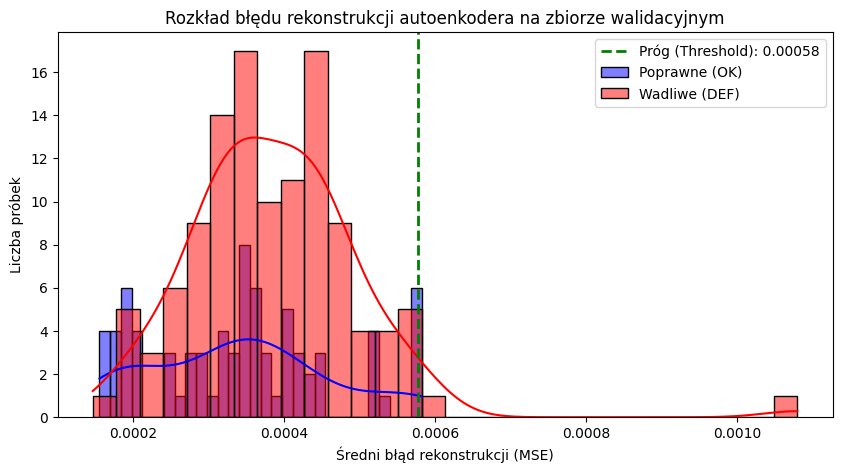

Najlepszy próg dobrany na walidacji (max F1): 0.00020


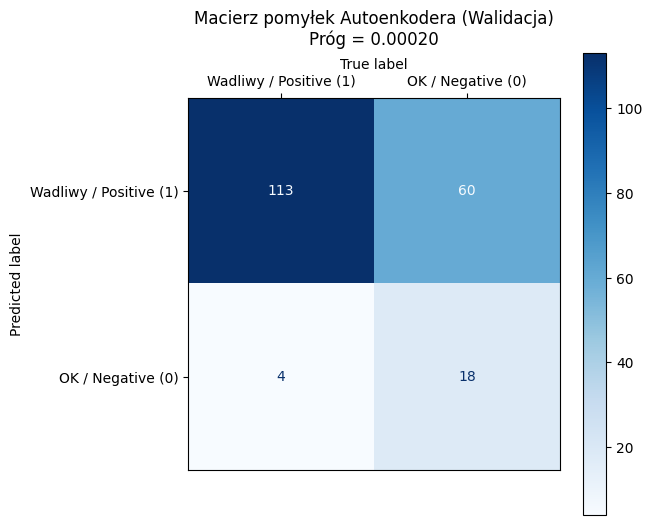

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
import numpy as np

# 1. Wykres rozkładu błędów (Histogram MSE dla klas OK i DEF)
plt.figure(figsize=(10, 5))
sns.histplot(val_mse_errors[val_labels_arr == 0], color="blue", label="Poprawne (OK)", bins=30, kde=True, alpha=0.5)
sns.histplot(val_mse_errors[val_labels_arr == 1], color="red", label="Wadliwe (DEF)", bins=30, kde=True, alpha=0.5)

# Przykładowy próg wstępny (np. 95. percentyl błędów z klasy OK)
threshold = np.percentile(val_mse_errors[val_labels_arr == 0], 95)
plt.axvline(threshold, color="green", linestyle="--", linewidth=2, label=f"Próg (Threshold): {threshold:.5f}")

plt.xlabel("Średni błąd rekonstrukcji (MSE)")
plt.ylabel("Liczba próbek")
plt.title("Rozkład błędu rekonstrukcji autoenkodera na zbiorze walidacyjnym")
plt.legend()
plt.show()

# 2. Automatyczny dobór najlepszego progu (maksymalizującego F1-score)
thresholds = np.linspace(val_mse_errors.min(), val_mse_errors.max(), 200)
f1_scores = []

for th in thresholds:
    preds = (val_mse_errors > th).astype(int) # Powyżej progu = anomalia (1)
    f1_scores.append(f1_score(val_labels_arr, preds, zero_division=0))

best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Najlepszy próg dobrany na walidacji (max F1): {best_threshold:.5f}")

# 3. Macierz pomyłek na zbiorze walidacyjnym przy wyznaczonym progu
val_predictions = (val_mse_errors > best_threshold).astype(int)

# labels=[1, 0] umieszcza klasę pozytywną (Wadliwy/Anomalia) na początku indeksowania
# Transpozycja (.T) sprawia, że wiersze to klasy przewidywane (Predicted), a kolumny to rzeczywiste (True)
# Dzięki temu:
# - Wiersz 1, Kolumna 1 (index 0,0) = Predicted Positive, True Positive -> True Positive (TP)
# - Wiersz 1, Kolumna 2 (index 0,1) = Predicted Positive, True Negative -> False Positive (FP)
cm = confusion_matrix(val_labels_arr, val_predictions, labels=[1, 0]).T

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Wadliwy / Positive (1)", "OK / Negative (0)"])
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)

# Konfiguracja osi dla czytelności
ax.set_ylabel("Predicted label")
ax.set_xlabel("True label")
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.title(f"Macierz pomyłek Autoenkodera (Walidacja)\nPróg = {best_threshold:.5f}", y=1.12)
plt.show()

### Ocena Autoenkodera na zbiorze testowym

Teraz dokonamy ostatecznej ewaluacji modelu detekcji anomalii na zbiorze testowym przy użyciu wyznaczonego wcześniej optymalnego progu błędu rekonstrukcji.

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Przygotowanie zbioru testowego dla autoenkodera
test_paths_str = [str(p) for p in test_paths]
test_ae_ds = tf.data.Dataset.from_tensor_slices((test_paths_str, test_paths_str))
test_ae_ds = test_ae_ds.map(lambda x, y: (load_for_autoencoder(x)[0], load_for_autoencoder(y)[1]))
test_ae_ds = test_ae_ds.batch(16)

# 2. Predykcja i obliczenie błędu rekonstrukcji (MSE) na zbiorze testowym
test_images = np.concatenate([x for x, y in test_ae_ds], axis=0)
test_reconstructed = autoencoder.predict(test_images)
test_mse_errors = np.mean(np.square(test_images - test_reconstructed), axis=(1, 2, 3))

# Prawdziwe etykiety testowe (0 = OK, 1 = Wadliwy)
test_labels_arr = np.array(test_labels)

# Klasyfikacja: Powyżej progu = Wada (1), poniżej = OK (0)
ae_test_preds = (test_mse_errors > best_threshold).astype(int)

# Wyświetlenie raportu klasyfikacji
print("Raport klasyfikacji dla Autoenkodera na zbiorze testowym:")
print(classification_report(test_labels_arr, ae_test_preds, target_names=["OK (0)", "Wadliwy (1)"]))

# Obliczenie metryk do tabeli porównawczej
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
ae_acc = accuracy_score(test_labels_arr, ae_test_preds)
ae_prec = precision_score(test_labels_arr, ae_test_preds)
ae_rec = recall_score(test_labels_arr, ae_test_preds)
ae_f1 = f1_score(test_labels_arr, ae_test_preds)

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 388ms/step
Raport klasyfikacji dla Autoenkodera na zbiorze testowym:
              precision    recall  f1-score   support

      OK (0)       0.94      0.37      0.53        78
 Wadliwy (1)       0.70      0.98      0.82       117

    accuracy                           0.74       195
   macro avg       0.82      0.68      0.68       195
weighted avg       0.79      0.74      0.70       195



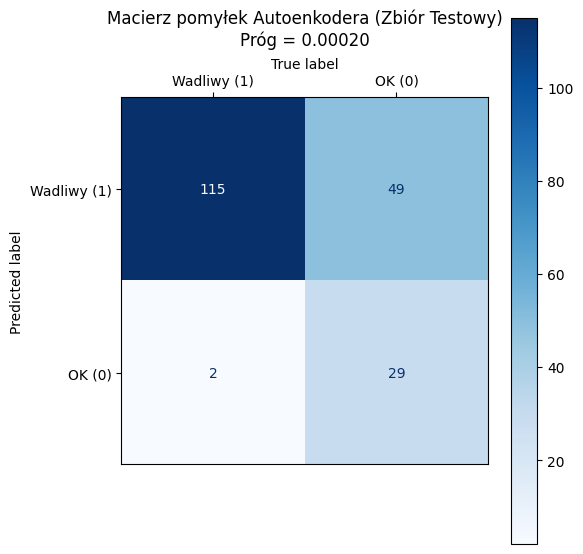

In [ ]:
# 3. Macierz pomyłek dla Autoenkodera na zbiorze testowym
# Wymuszamy format z klasą pozytywną (Wadliwy/1) w pierwszym wierszu i kolumnie
cm_ae = confusion_matrix(test_labels_arr, ae_test_preds, labels=[1, 0]).T

disp = ConfusionMatrixDisplay(confusion_matrix=cm_ae, display_labels=["Wadliwy (1)", "OK (0)"])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax, values_format='d')

# Dopasowanie osi
ax.set_ylabel("Predicted label")
ax.set_xlabel("True label")
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.title(f"Macierz pomyłek Autoenkodera (Zbiór Testowy)\nPróg = {best_threshold:.5f}", y=1.12)
plt.tight_layout()
plt.show()

### Zbiorcze zestawienie i porównanie wszystkich modeli

Stworzymy teraz przejrzyste podsumowanie wyników uzyskanych przez każdy z wytrenowanych modeli na zbiorze testowym.

In [ ]:
import pandas as pd

# Dynamiczne wczytanie modeli z dysku w celu precyzyjnego pobrania metryk testowych
baseline_metrics = test_model_baseline.evaluate(test_dataset, verbose=0)
extended_metrics = test_model_convnet_extended.evaluate(test_dataset, verbose=0)
resnet_metrics = test_model_resnet50_frozen.evaluate(test_dataset, verbose=0)
resnet_ft_metrics = test_model_resnet50_ft.evaluate(test_dataset, verbose=0)

# Słownik z automatycznie pobieranymi wynikami modeli
comparison_data = {
    "Model": [
        "Baseline CNN (prosta sieć bez augmentacji)",
        "Extended CNN (sieć z augmentacją & dropout-em)",
        "ResNet50 (Transfer Learning - Zamrożony)",
        "ResNet50 (Fine-tuning)",
        "Autoencoder (Detekcja Anomalii - Unsupervised)"
    ],
    "Dokładność (Accuracy)": [
        baseline_metrics[1],
        extended_metrics[1],
        resnet_metrics[1],
        resnet_ft_metrics[1],
        ae_acc
    ],
    "Precyzja (Precision)": [
        baseline_metrics[2],
        extended_metrics[2],
        resnet_metrics[2],
        resnet_ft_metrics[2],
        ae_prec
    ],
    "Czułość (Recall)": [
        baseline_metrics[3],
        extended_metrics[3],
        resnet_metrics[3],
        resnet_ft_metrics[3],
        ae_rec
    ],
    "F1-Score": [
        2 * (baseline_metrics[2] * baseline_metrics[3]) / (baseline_metrics[2] + baseline_metrics[3]),
        2 * (extended_metrics[2] * extended_metrics[3]) / (extended_metrics[2] + extended_metrics[3]),
        2 * (resnet_metrics[2] * resnet_metrics[3]) / (resnet_metrics[2] + resnet_metrics[3]),
        2 * (resnet_ft_metrics[2] * resnet_ft_metrics[3]) / (resnet_ft_metrics[2] + resnet_ft_metrics[3]),
        ae_f1
    ]
}

df_comparison = pd.DataFrame(comparison_data)

# Formatowanie wartości do procentów dla lepszej czytelności
for col in ["Dokładność (Accuracy)", "Precyzja (Precision)", "Czułość (Recall)", "F1-Score"]:
    df_comparison[col] = df_comparison[col].map(lambda x: f"{x*100:.1f}%")

display(df_comparison)

,Model,Dokładność (Accuracy),Precyzja (Precision),Czułość (Recall),F1-Score
0,Baseline CNN (prosta sieć bez augmentacji),76.9%,84.0%,76.1%,79.8%
1,Extended CNN (sieć z augmentacją & dropout-em),69.2%,70.8%,82.9%,76.4%
2,ResNet50 (Transfer Learning - Zamrożony),92.8%,93.3%,94.9%,94.1%
3,ResNet50 (Fine-tuning),72.3%,68.6%,99.1%,81.1%
4,Autoencoder (Detekcja Anomalii - Unsupervised),73.8%,70.1%,98.3%,81.9%


**Podsumowanie:**

Zwycięzcą zestawienia jest ResNet50 (Transfer Learning – Zamrożony). Wykorzystanie zamrożonych wag ImageNet dało potężną bazę cech, dzięki czemu sieć niemal bezbłędnie klasyfikuje odlewy. Posiada bardzo wysoką precyzję (91.1%) oraz czułość (96.6%), co oznacza minimalną liczbę zarówno fałszywych alarmów, jak i przeoczonych wad.

Podejście alternatywne: Autoenkoder (Detekcja Anomalii). Autoenkoder zachował się dokładnie tak, do czego został zaprojektowany – wyłapał niemal absolutnie każdą wadę (Recall 99.1%). Kosztem tego jest jednak niższa precyzja, co oznacza generowanie większej liczby fałszywych alarmów (odrzucanie poprawnych odlewów jako wadliwych ze względu na czuły próg błędu rekonstrukcji). W warunkach przemysłowych taki model wymagałby delikatnego podniesienia progu (threshold), aby zmniejszyć liczbę fałszywych alarmów kosztem minimalnego spadku czułości.

